# Compact left-aligned mixed-length training — sequence PE: **fixed sinusoidal (base 10,000, added once to the input embedding, scale 1)**

**Question.** Models are trained FROM SCRATCH only on final outputs of composite instructions (effective lengths
0, 2, 3, 4, 5; **never** a single operation) and tested on the never-trained single operations A, B, C.

**Training support (identical in notebooks 07 and 08; 361 words):** EMPTY; all 9 length-2 words (AA..CC); all 27
length-3, 81 length-4 and 243 length-5 words. Lengths are sampled 20% each and words are balanced within a length.
The budget is seed 42, 5000 updates x batch 256 = 1,280,000 examples per run. Every model and both PE conditions see
the SAME logical example sequence.

**Compact layout.** The j-th operation always occupies slot j; the remaining slots are PAD (masked as attention
keys). Grid and output tokens keep fixed offsets (AR: 82 tokens, `<OUTPUT>` at 44, answers 45..80, `<EOS>` 81).
There is no random placement in these runs.

**The ONLY difference between 07 and 08 is the 1D sequence positional encoding of the seven attention models.**
Both use the same deterministic layout position IDs and keep the same additive grid row/column (ViT: patch
row/column) and segment/type embeddings. Neither has a learned 1D position or slot table. This controls 1D sequence
PE conditional on the shared spatial encoding; it is not a comparison of 2D schemes.

**Shared CNN controls.** ResCNN-FiLM and U-Net-FiLM have no attention PE. They are trained once in `shared_cnn/` and
reused by whichever notebook runs second, but only when the configuration hashes match. They are reported once and
are n/a for the PE contrast.

**Test.** The selected checkpoint (lowest length-macro validation CE on lengths 0/2/3/4/5) is evaluated on all 364
words of length 0..5 x 1000 held-out grids, using compact left alignment. AR decoding is free-running. Lengths 2-5 are
seen strings on new grids; the singles are the only held-out strings.

**Limits.** One seed. Differences from notebooks 04/05 change BOTH the placement distribution and the PE, so they do
not isolate placement. Behavioural diagnostics are non-causal.


In [2]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 4e5b1858d792d7b3c7df14011c5127adff7e12c8


In [3]:
# --- CONFIGURATION ---------------------------------------------------------------------------------------
PE = "sinusoidal"                                   # 1D sequence PE for the attention models of THIS notebook
MODE = os.environ.get("DECOMP_MODE", "full")  # "full" = requested benchmark | "smoke" = tiny CPU integration run
SEED = 42
ATTN_MODELS = os.environ.get("DECOMP_ATTN_MODELS", "transformer_ar,looped_transformer_ar,transformer_encoder,"
                             "looped_transformer_encoder,vit,looped_vit,trm").split(",")
CNN_CONTROLS = os.environ.get("DECOMP_CNN_MODELS", "rescnn_film,unet_film").split(",")
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE
    else "/content/decompositionality_results" if IN_COLAB else str(REPO_DIR / "results"))
COMPACT_ROOT = f"{RESULTS_ROOT}/compact_02345_pe"   # NEW subtree (manifests/, rope/, sinusoidal/, shared_cnn/, comparisons/)
RESUME = True
OPTIMIZER_STEPS = None          # None = mode default (full: 5000)
EFFECTIVE_BATCH = None          # None = mode default (full: 256)
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
DTYPE = "auto"
MICROBATCH = None
EVAL_CHUNK_GRIDS = 100
ANALYSIS_CHUNK_SIZE = 2000
USE_ANALYSIS_CACHE = True
RUN_PROFILE = True
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
from decompositionality.config import make_experiment_config
_over = dict(seed=SEED, device=DEVICE, dtype=DTYPE, microbatch_size=MICROBATCH)
if OPTIMIZER_STEPS: _over["optimizer_steps"] = OPTIMIZER_STEPS
if EFFECTIVE_BATCH: _over["effective_batch_size"] = EFFECTIVE_BATCH
cfg_pe = make_experiment_config(f"compact_02345_{PE}", MODE, COMPACT_ROOT, ATTN_MODELS, **_over)
cfg_cnn = make_experiment_config("compact_02345_cnn", MODE, COMPACT_ROOT, CNN_CONTROLS, **_over)
for c in (cfg_pe, cfg_cnn):
    c.resume = RESUME
if MODE == "smoke":
    print("*** SMOKE MODE: tiny integration run; NOT scientific results ***")
print(f"PE={PE} | mode={MODE} | steps={cfg_pe.train.optimizer_steps} | batch={cfg_pe.train.effective_batch_size} | "
      f"seed={SEED} | slots={cfg_pe.n_slots} | placement=compact_left")
print("attention runs ->", cfg_pe.experiment_dir, "| shared CNN controls ->", cfg_cnn.experiment_dir,
      "| shared manifests ->", cfg_pe.manifest_dir)


Mounted at /content/drive
PE=sinusoidal | mode=full | steps=5000 | batch=256 | seed=42 | slots=5 | placement=compact_left
attention runs -> /content/drive/MyDrive/decompositionality_results/compact_02345_pe/sinusoidal | shared CNN controls -> /content/drive/MyDrive/decompositionality_results/compact_02345_pe/shared_cnn | shared manifests -> /content/drive/MyDrive/decompositionality_results/compact_02345_pe/manifests


In [4]:
import json, torch
from decompositionality.utils import environment_info
ENV_INFO = environment_info(REPO_DIR)
print(json.dumps(ENV_INFO, indent=1))


{
 "python": "3.13.16",
 "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "torch": "2.14.1+cu130",
 "numpy": "2.4.6",
 "cuda_available": true,
 "repo_commit": "4e5b1858d792d7b3c7df14011c5127adff7e12c8",
 "pandas": "2.2.3",
 "matplotlib": "3.10.0",
 "gpu": "NVIDIA A100-SXM4-40GB",
 "cuda": "13.0",
 "bf16_supported": true,
 "gpu_total_memory_gb": 39.49
}


In [5]:
# --- Validate supports, compact layout, offsets, PE wiring and manifests --------------------------------------
import dataclasses, hashlib
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from decompositionality import mixed as M, tokenization as T
from decompositionality.mixed_pipeline import prepare_mixed
from decompositionality.models.registry import build_model, default_config
from decompositionality.models.common import count_parameters
sup = M.support(cfg_pe.experiment)
assert {L: len(w) for L, w in sup.items()} == {0: 1, 2: 9, 3: 27, 4: 81, 5: 243} and len(cfg_pe.train_strings) == 361
assert len(M.test_words()) == 364 and not any(len(w) == 1 for w in M.training_words(cfg_pe.experiment))
lay = T.ARLayout(5)
assert (lay.length, lay.idx_output, lay.out_start, lay.out_start + 35, lay.idx_eos) == (82, 44, 45, 80, 81)
_s = M.MixedTrainStream(SEED, cfg_pe.experiment, 256)
_o = M.MixedTrainStream(SEED, "compact_02345_sinusoidal" if PE == "rope" else "compact_02345_rope", 256)
for step in (0, 1, 2):
    a, b = _s.batch(step), _o.batch(step)
    assert all(np.array_equal(a[k], b[k]) for k in ("x", "y", "ops", "string", "length")), "PE conditions differ in data"
    for ops, L in zip(a["ops"], a["length"]):
        assert (ops[:L] != 3).all() and (ops[L:] == 3).all(), "not compact left-aligned"
print("compact left alignment + identical logical data stream across PE conditions: OK")
init_rows = []
for m in ATTN_MODELS:
    tensors = {}
    for pe in ("rope", "sinusoidal"):
        c = dataclasses.asdict(default_config(m)); c.update(n_slots=5, sequence_pe=pe)
        mod = build_model(m, c, seed=SEED)
        tensors[pe] = {k: v.detach().clone() for k, v in mod.named_parameters()}
        assert not any("pos_emb" in k or "slot_emb" in k for k in tensors[pe]), "learned 1D position table present"
    same = tensors["rope"].keys() == tensors["sinusoidal"].keys() and all(
        torch.equal(tensors["rope"][k], tensors["sinusoidal"][k]) for k in tensors["rope"])
    h = hashlib.sha256(b"".join(v.numpy().tobytes() for v in tensors[PE].values())).hexdigest()[:16]
    init_rows.append({"model": m, "unique_params": sum(v.numel() for v in tensors[PE].values()),
                      "identical_initial_trainable_tensors_rope_vs_sinusoidal": same, "init_sha256": h})
    assert same, m
init_df = pd.DataFrame(init_rows); display(init_df)
ctx_pe = prepare_mixed(cfg_pe, repo_dir=str(REPO_DIR), legacy_manifest=f"{RESULTS_ROOT}/distinct_pairs/manifests/manifest.json")
ctx_cnn = prepare_mixed(cfg_cnn, repo_dir=str(REPO_DIR), legacy_manifest=f"{RESULTS_ROOT}/distinct_pairs/manifests/manifest.json")
assert ctx_pe.manifests.manifest_hash == ctx_cnn.manifests.manifest_hash
cfg_pe.experiment_dir.mkdir(parents=True, exist_ok=True)
init_df.to_csv(cfg_pe.experiment_dir / "initialization_checksums.csv", index=False)
print("validation records per length:", pd.Series(ctx_pe.val_set["length"]).value_counts().sort_index().to_dict())


compact left alignment + identical logical data stream across PE conditions: OK


,model,unique_params,identical_initial_trainable_tensors_rope_vs_sinusoidal,init_sha256
0,transformer_ar,10670611,True,92a06239a35365da
1,looped_transformer_ar,1798291,True,f341c0a6ad9095b5
2,transformer_encoder,10662154,True,5ac33fde97aeea14
3,looped_transformer_encoder,1789834,True,f548f478958116e7
4,vit,10683304,True,f847227bd3d341a3
5,looped_vit,1810984,True,6d9729f558376f47
6,trm,9936640,True,d1084cd4c4a5ecab


Manifests /content/drive/MyDrive/decompositionality_results/compact_02345_pe/manifests (hash bdf24c327a65; identical to legacy manifests) | validation 1500 records (300 grids x 5 lengths) | fixed validation subset 160 | test 364,000 (1000 grids x 364 words)
Manifests /content/drive/MyDrive/decompositionality_results/compact_02345_pe/manifests (hash bdf24c327a65; identical to legacy manifests) | validation 1500 records (300 grids x 5 lengths) | fixed validation subset 160 | test 364,000 (1000 grids x 364 words)
validation records per length: {0: 300, 2: 300, 3: 300, 4: 300, 5: 300}


In [6]:
# --- Parameter counts / time estimate -------------------------------------------------------------------------
from decompositionality.mixed_reports import resource_table
from decompositionality.training import profile_model
display(resource_table(cfg_pe.experiment_dir, cfg_pe.experiment_dir / "tables", PE, ATTN_MODELS))
if RUN_PROFILE and torch.cuda.is_available():
    prof = pd.DataFrame([profile_model(m, cfg_pe.train, n_steps=2, n_slots=5, sequence_pe=PE) for m in ATTN_MODELS])
    display(prof)


,model,display_name,n_slots,sequence_pe,unique_learned_params,shared_core_params,untied_equivalent_params,param_note,block_applications_per_forward,core_calls_per_forward,input_tokens,decoded_output_steps,training_objective
0,transformer_ar,Transformer AR,5,sinusoidal,10670611,NaN,NaN,,6,6,81 (teacher forcing); prompt 45,36,AR teacher-forced NLL (36 answer cells + EOS)
1,looped_transformer_ar,Looped Transformer AR (tied),5,sinusoidal,1798291,1774464.0,10670611.0,weight-tied (~1.8M unique; NOT a 10M model),6,6,81 (teacher forcing); prompt 45,36,AR teacher-forced NLL (36 answer cells + EOS)
2,transformer_encoder,Transformer encoder,5,sinusoidal,10662154,NaN,NaN,,6,6,41 (5 op slots + 36 cells),1,parallel cell CE
3,looped_transformer_encoder,Looped Transformer encoder (tied),5,sinusoidal,1789834,1774464.0,10662154.0,weight-tied (~1.8M unique; NOT a 10M model),6,6,41 (5 op slots + 36 cells),1,parallel cell CE
4,vit,ViT (2x2 patches),5,sinusoidal,10683304,NaN,NaN,,6,6,14 (5 op slots + 9 patches),1,parallel cell CE
5,looped_vit,Looped ViT (tied baseline),5,sinusoidal,1810984,1774464.0,10683304.0,weight-tied (~1.8M unique; NOT a 10M model),6,6,14 (5 op slots + 9 patches),1,parallel cell CE
6,trm,TRM-adapted,5,sinusoidal,9936640,9912320.0,NaN,,24,12,41 (5 op slots + 36 cells),1,TRM deep-supervision loss (mean cell CE over S...


,model_id,sec_per_step,microbatch,est_train_minutes,peak_gpu_gb
0,transformer_ar,0.030945,256,2.578775,1.961803
1,looped_transformer_ar,0.029499,256,2.458225,1.844828
2,transformer_encoder,0.018432,256,1.536032,1.083406
3,looped_transformer_encoder,0.016217,256,1.351376,0.964596
4,vit,0.017157,256,1.429737,0.483360
5,looped_vit,0.015029,256,1.252413,0.361742
6,trm,0.081236,256,6.769707,3.491256


In [7]:
# --- Train sequentially: 7 attention models (this PE), then the shared CNN controls (skipped if complete) ------
from decompositionality.training import train_model
from decompositionality.utils import free_memory
failures = {}
for cfg_, ctx_ in ((cfg_pe, ctx_pe), (cfg_cnn, ctx_cnn)):
    for mid in cfg_.models:
        print(f"\n=== training {cfg_.experiment}/{mid} ===")
        try:
            train_model(mid, cfg_, ctx_.manifests, ctx_.val_set, ctx_.subset_set, repo_dir=str(REPO_DIR))
        except Exception as exc:
            import traceback; traceback.print_exc(); failures[f"{cfg_.experiment}/{mid}"] = repr(exc)
        finally:
            free_memory()
if failures:
    raise RuntimeError(f"training failed: {failures}")



=== training compact_02345_sinusoidal/transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,670,611 params | device NVIDIA A100-SXM4-40GB | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 2.3048 (best) | subset(160) exact 0.000 cell 0.097
  step 500/5000 loss 1.7085 lr 2.98e-04 | 24.41 steps/s, 6250 ex/s | ETA 3.1 min
  [val @ 500] cell CE 1.7574 (best) | subset(160) exact 0.219 cell 0.352
  [val @ 750] cell CE 1.4938 (best) | subset(160) exact 0.219 cell 0.420
  step 975/5000 loss 1.1922 lr 2.85e-04 | 23.80 steps/s, 6092 ex/s | ETA 2.8 min
  [val @ 1000] cell CE 1.1915 (best) | subset(160) exact 0.225 cell 0.509
  [val @ 1250] cell CE 0.7781 (best) | subset(160) exact 0.306 cell 0.649
  step 1450/5000 loss 0.4991 lr 2.60e-04 | 23.57 steps/s, 6034 ex/s | ETA 2.5 min
  [val @ 1500] cell CE 0.3981 (best) | subset(160) exact 0.487 cell 0.803
  [val @ 1750] cell CE 0.1277 (best) | subset(160) exact 0.675 cell 0.947
  step 1925/5000 loss 0.0521 lr 2.2

In [8]:
# --- Evaluate the SELECTED checkpoints on all 364 words x 1000 test grids (chunked, restartable) --------------
from decompositionality.mixed_pipeline import evaluate_mixed_model
failures = {}
for cfg_, ctx_ in ((cfg_pe, ctx_pe), (cfg_cnn, ctx_cnn)):
    for mid in cfg_.models:
        try:
            evaluate_mixed_model(mid, ctx_, chunk_grids=EVAL_CHUNK_GRIDS)
        except Exception as exc:
            import traceback; traceback.print_exc(); failures[f"{cfg_.experiment}/{mid}"] = repr(exc)
        finally:
            free_memory()
if failures:
    raise RuntimeError(f"evaluation failed: {failures}")


  [transformer_ar] test chunk 1/10 (36,400 records) | elapsed 0.4 min
  [transformer_ar] test chunk 2/10 (36,400 records) | elapsed 0.9 min
  [transformer_ar] test chunk 3/10 (36,400 records) | elapsed 1.3 min
  [transformer_ar] test chunk 4/10 (36,400 records) | elapsed 1.8 min
  [transformer_ar] test chunk 5/10 (36,400 records) | elapsed 2.2 min
  [transformer_ar] test chunk 6/10 (36,400 records) | elapsed 2.6 min
  [transformer_ar] test chunk 7/10 (36,400 records) | elapsed 3.1 min
  [transformer_ar] test chunk 8/10 (36,400 records) | elapsed 3.5 min
  [transformer_ar] test chunk 9/10 (36,400 records) | elapsed 4.0 min
  [transformer_ar] test chunk 10/10 (36,400 records) | elapsed 4.4 min
[transformer_ar] selected step 4500 | singles A/B/C exact 0/0/0 of 1000 each | EMPTY 1.0000 | seen pairs 1.0000 | eval 4.4 min
  [looped_transformer_ar] test chunk 1/10 (36,400 records) | elapsed 0.4 min
  [looped_transformer_ar] test chunk 2/10 (36,400 records) | elapsed 0.9 min
  [looped_transfor

# compact_02345_sinusoidal: singles (never trained) vs seen support

Integer exact successes / records on the held-out test grids. Lengths 3-5 are SEEN strings on NEW grids (not unseen-combination generalization). Overall micro = record-weighted over 364 words (dominated by length 5); length-macro = lengths 0..5 equally weighted. One seed; no error bars.

seen_support_fit = INADEQUATE if any seen category (pairs, len3, len4, len5) is below 0.9: single-operation failure of such a model is NOT a clean decomposition failure.

| model | selected_step | A | B | C | singles_macro_exact | EMPTY | seen_pairs | unseen_pairs | len3 | len4 | len5 | overall_micro | overall_length_macro | seen_support_fit |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Transformer AR | 4500 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 9000/9000 | N/A | 26999/27000 | 80987/81000 | 241750/243000 | 0.9883 | 0.8324 | adequate |
| Looped Transformer AR (tied) | 4750 | 0/1000 | 0/1000 | 0/1000 | 0.

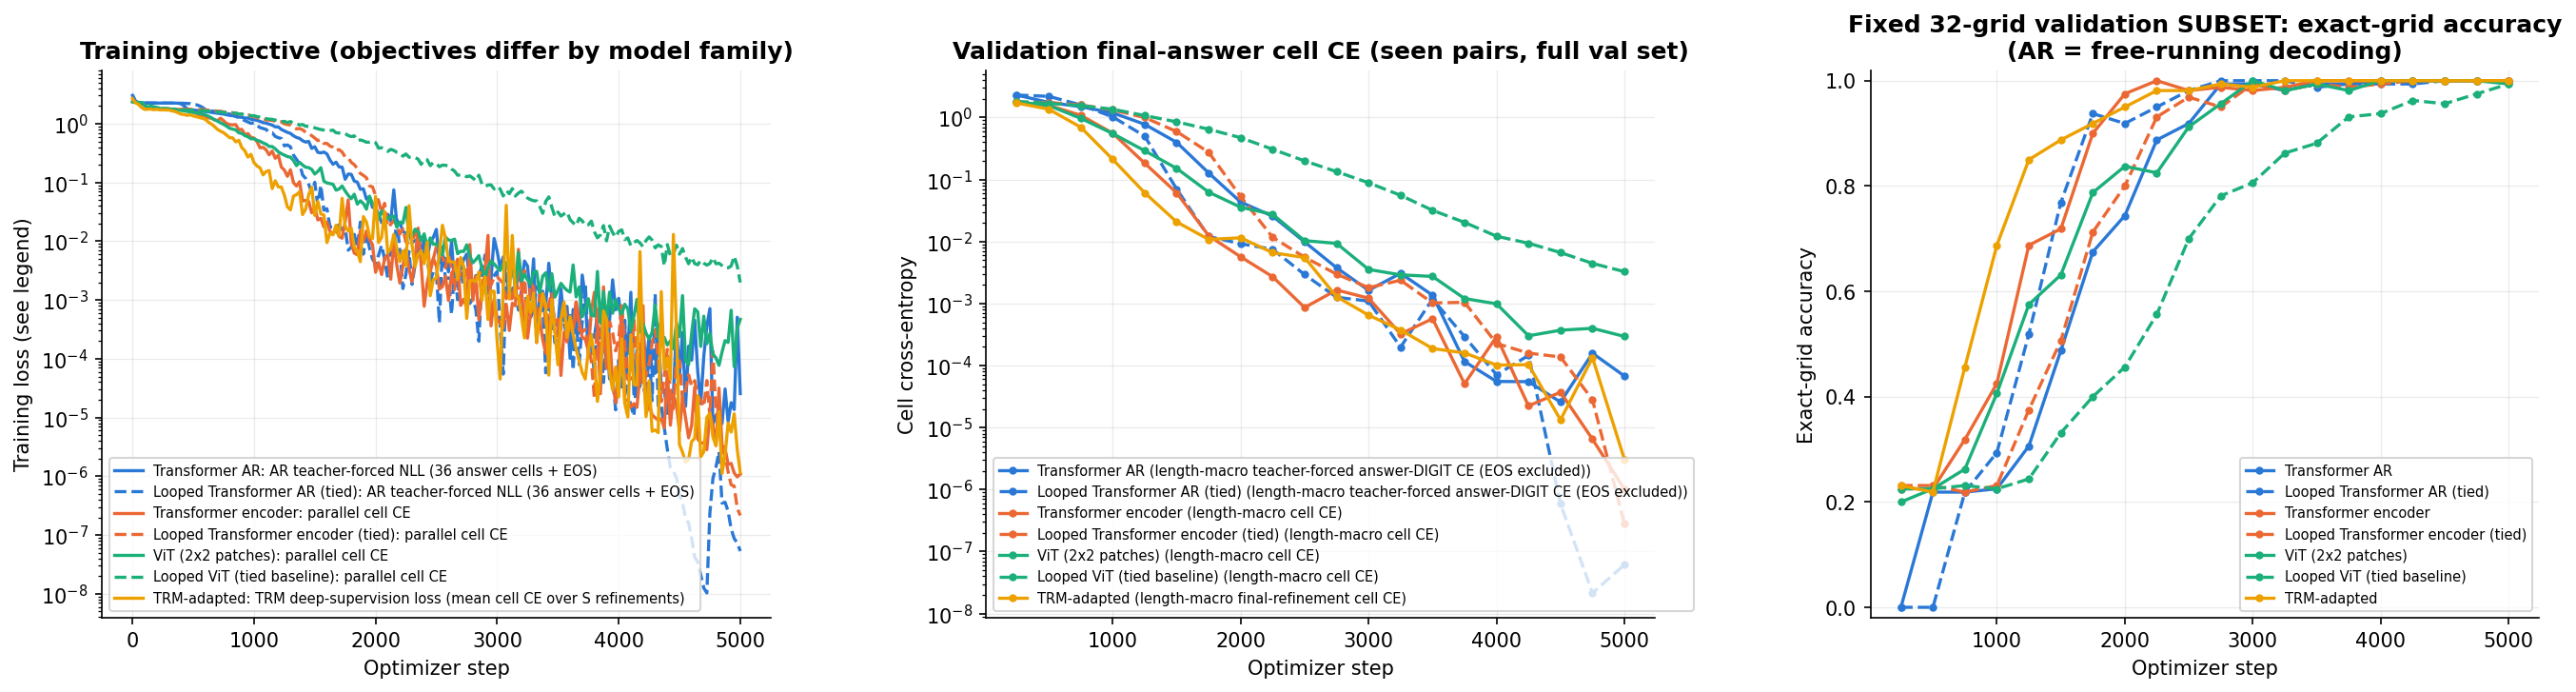

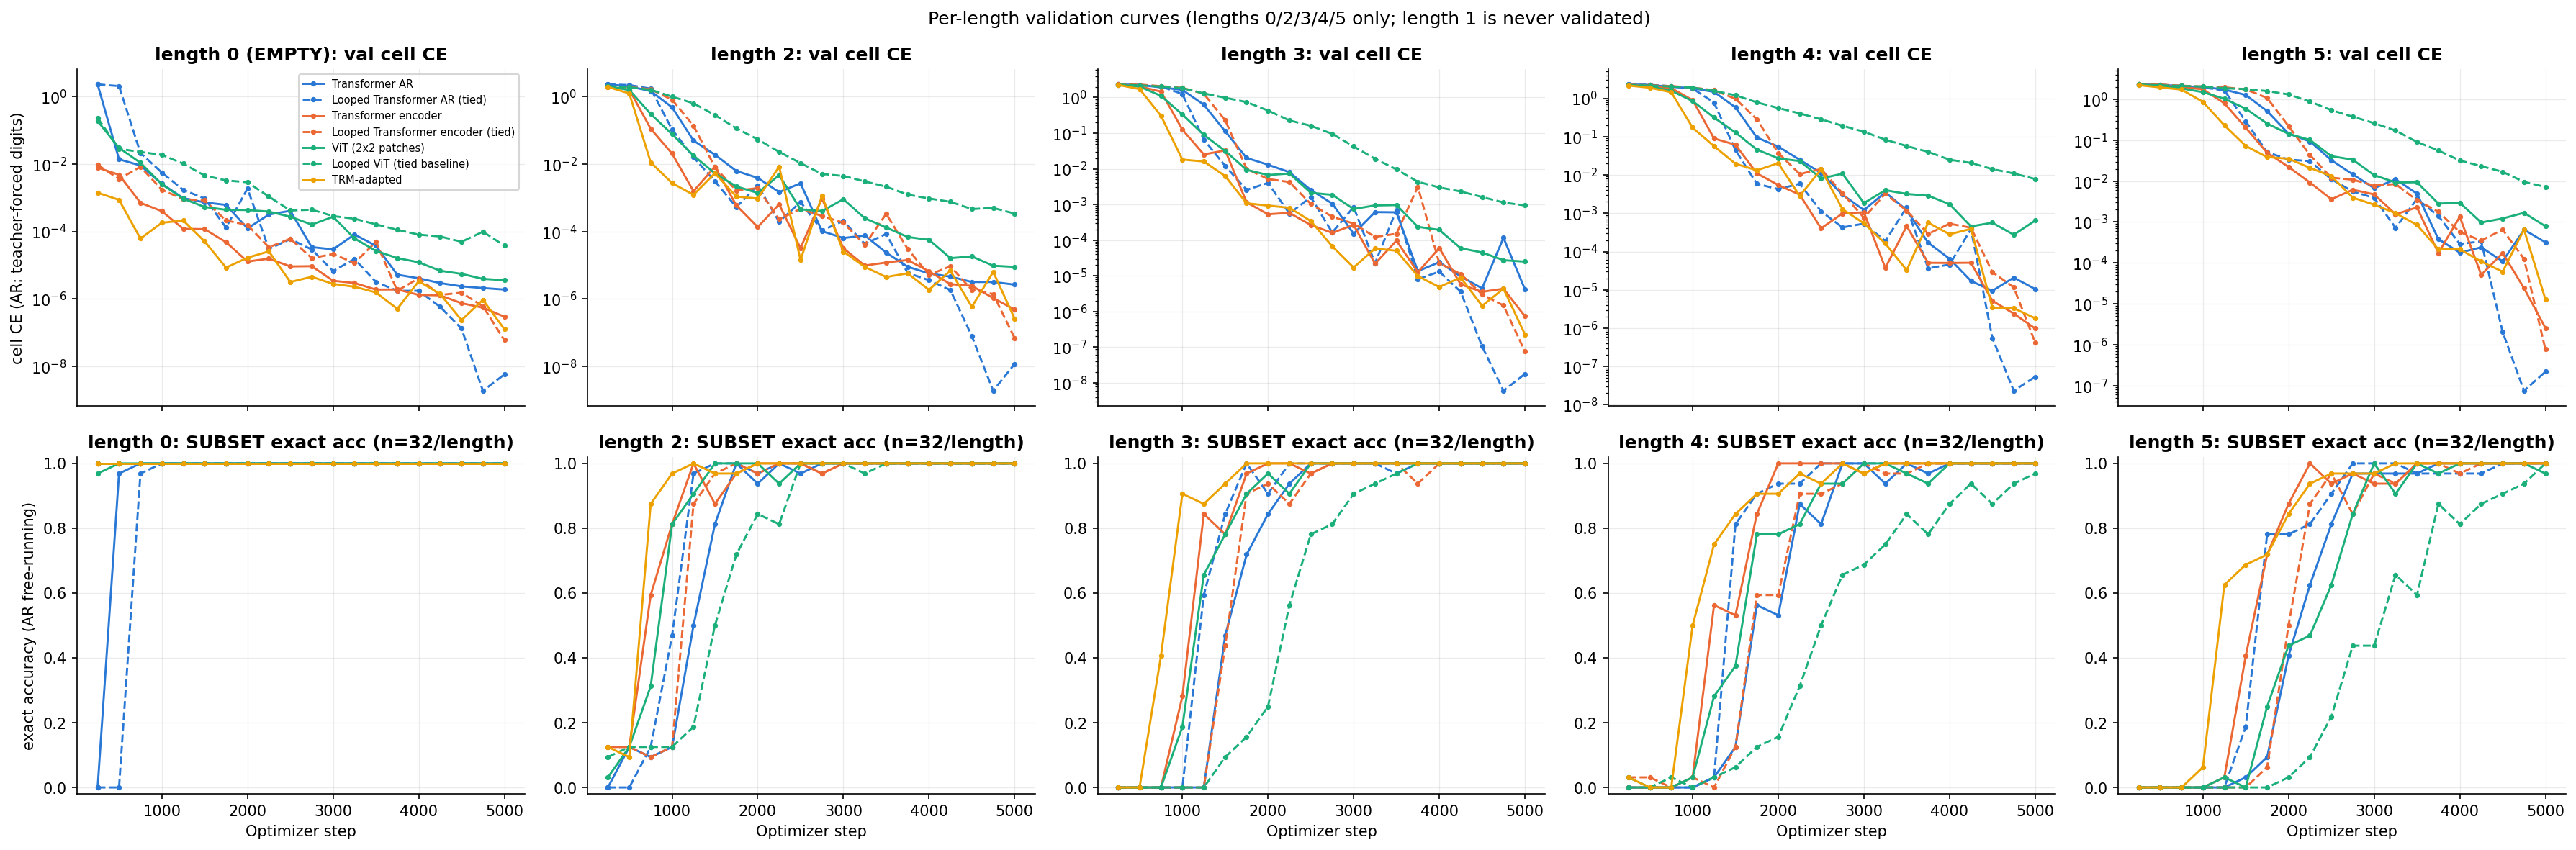

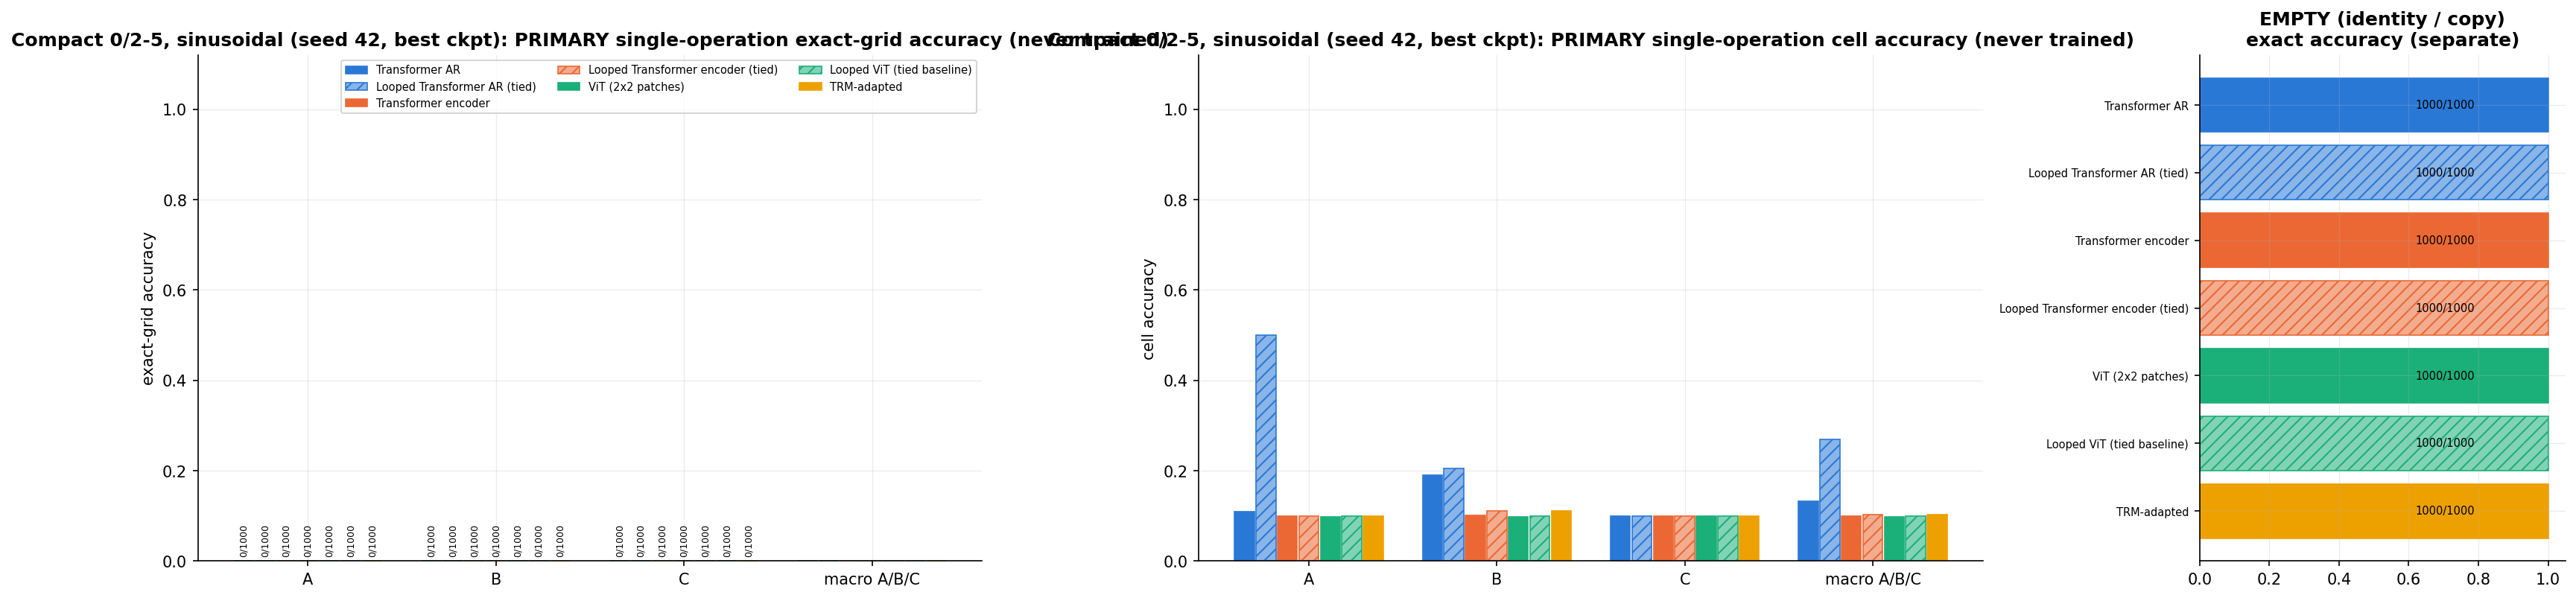

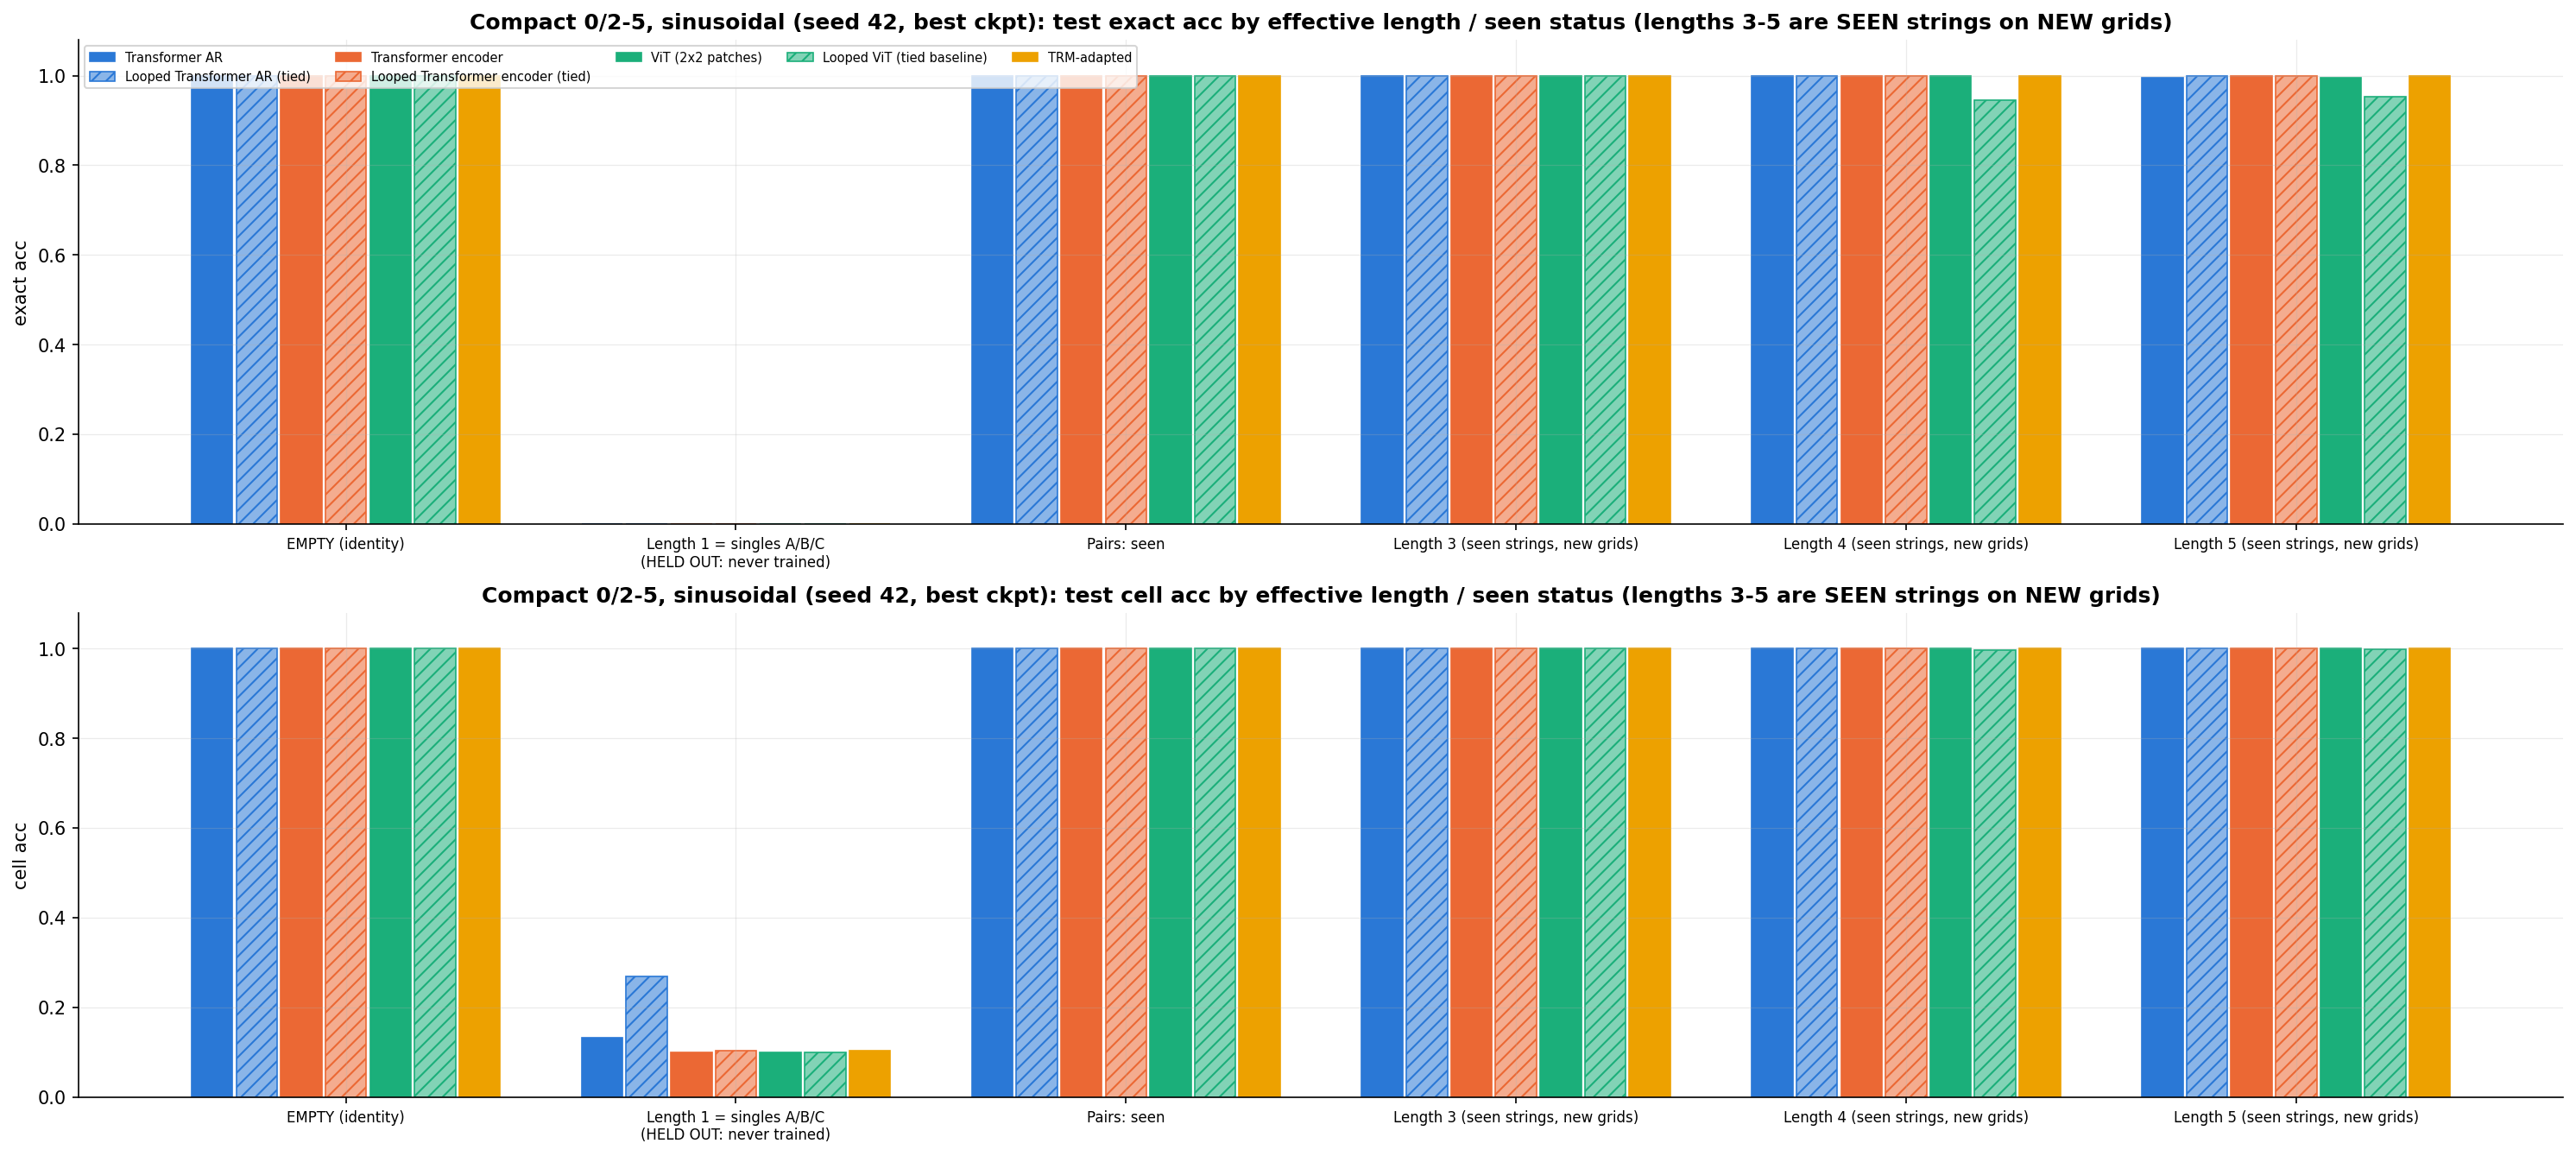

# compact_02345_cnn: singles (never trained) vs seen support

Integer exact successes / records on the held-out test grids. Lengths 3-5 are SEEN strings on NEW grids (not unseen-combination generalization). Overall micro = record-weighted over 364 words (dominated by length 5); length-macro = lengths 0..5 equally weighted. One seed; no error bars.

seen_support_fit = INADEQUATE if any seen category (pairs, len3, len4, len5) is below 0.9: single-operation failure of such a model is NOT a clean decomposition failure.

| model | selected_step | A | B | C | singles_macro_exact | EMPTY | seen_pairs | unseen_pairs | len3 | len4 | len5 | overall_micro | overall_length_macro | seen_support_fit |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ResCNN-FiLM | 4750 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 9000/9000 | N/A | 27000/27000 | 80995/81000 | 242956/243000 | 0.9916 | 0.8333 | adequate |
| U-Net-FiLM | 5000 | 0/1000 | 0/1000 | 0/1000 | 0.0000 | 1000/1000 | 9000/9000

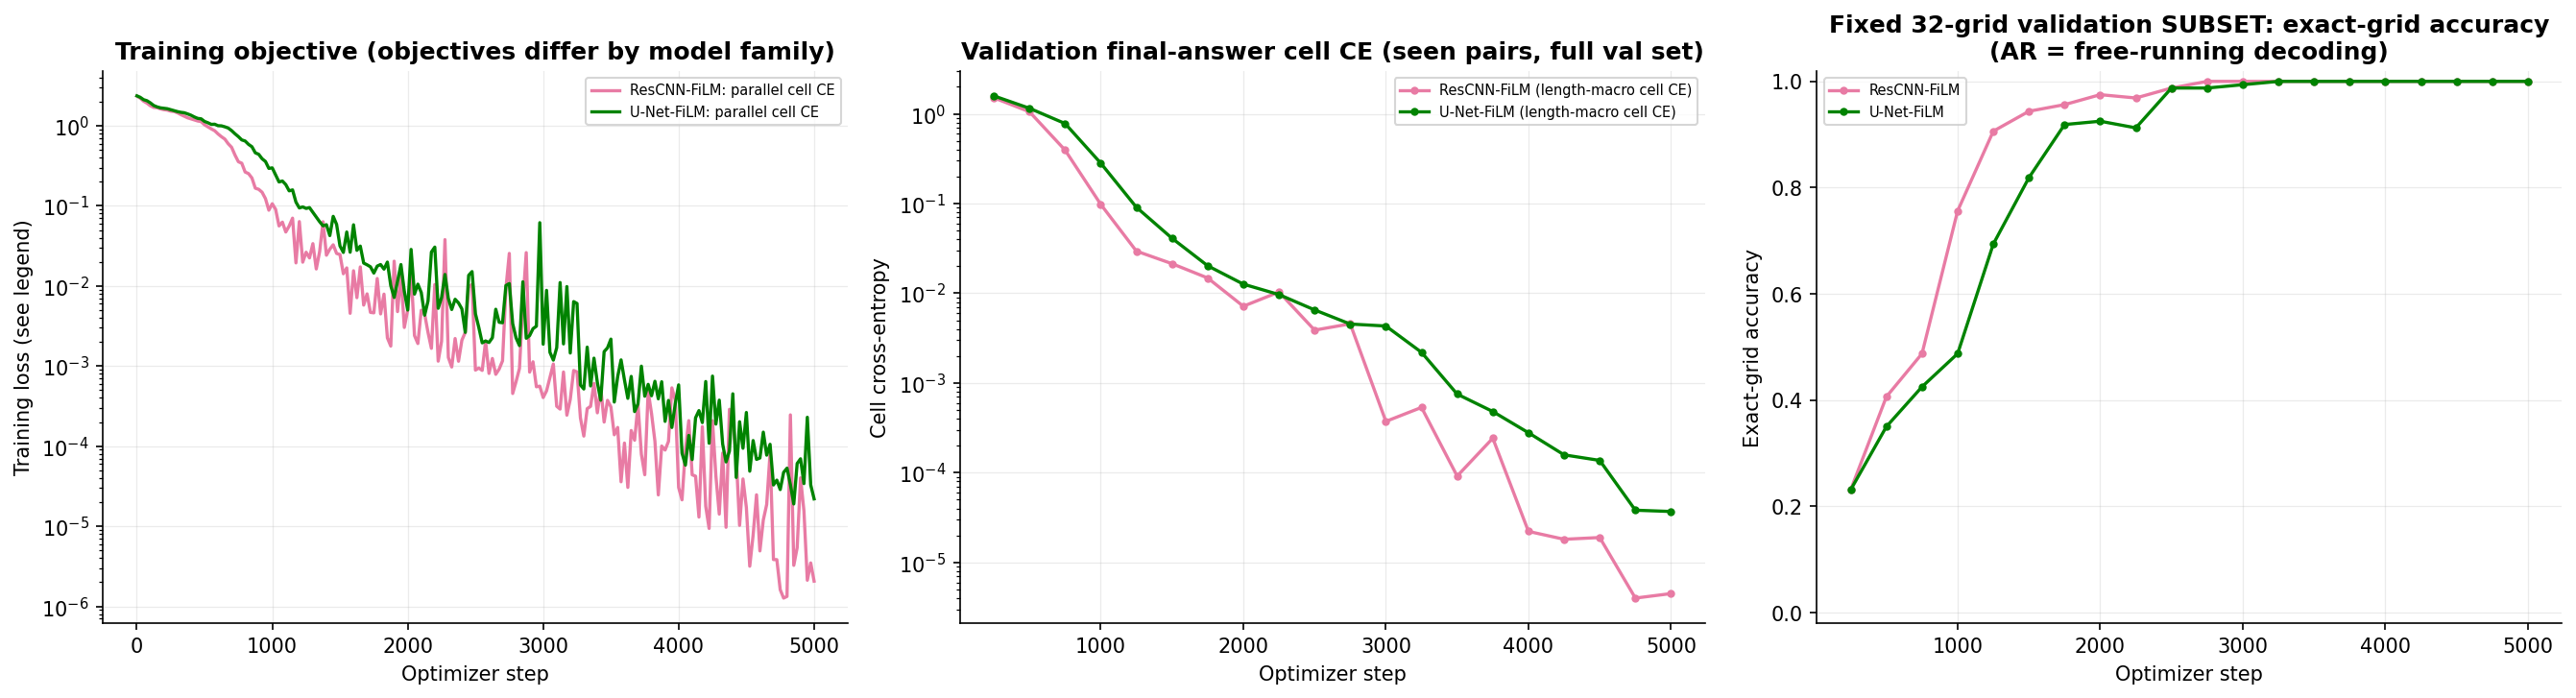

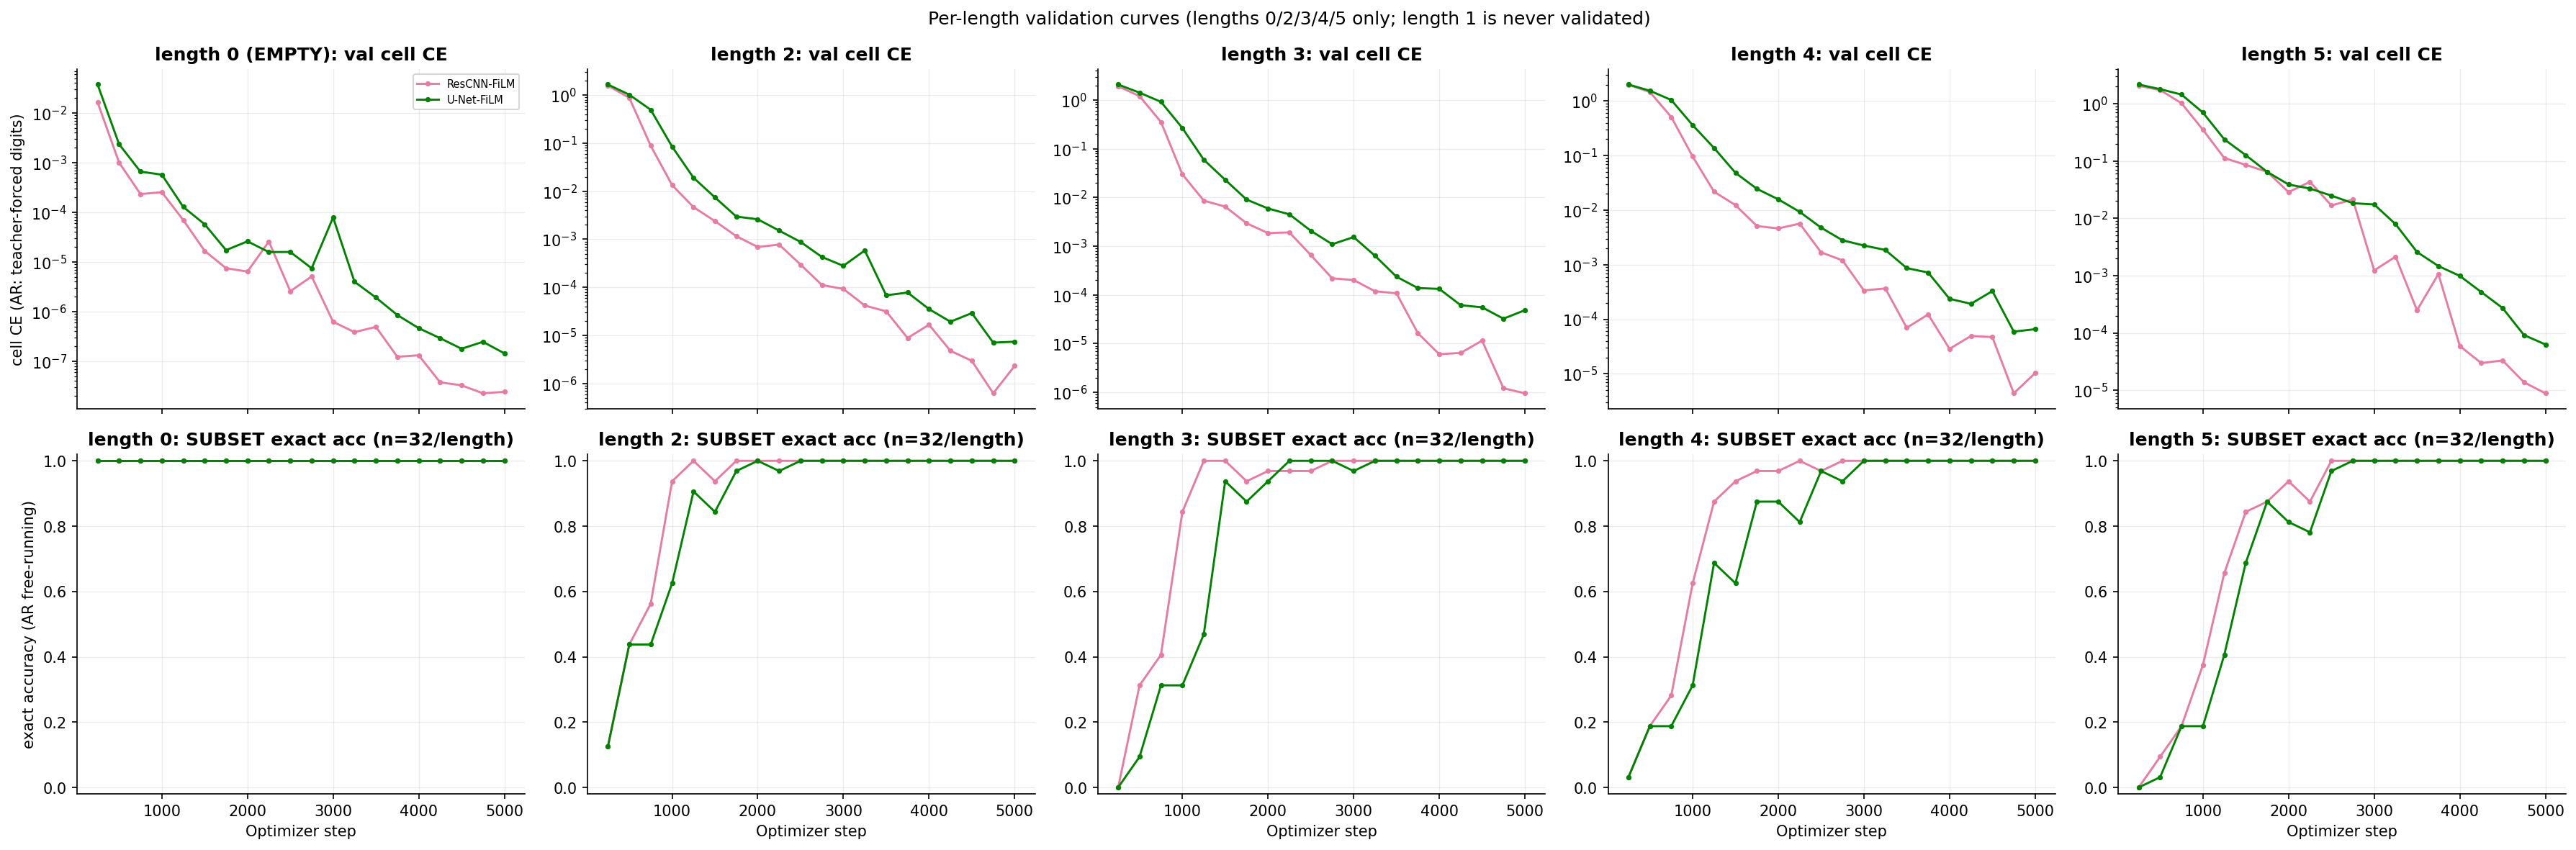

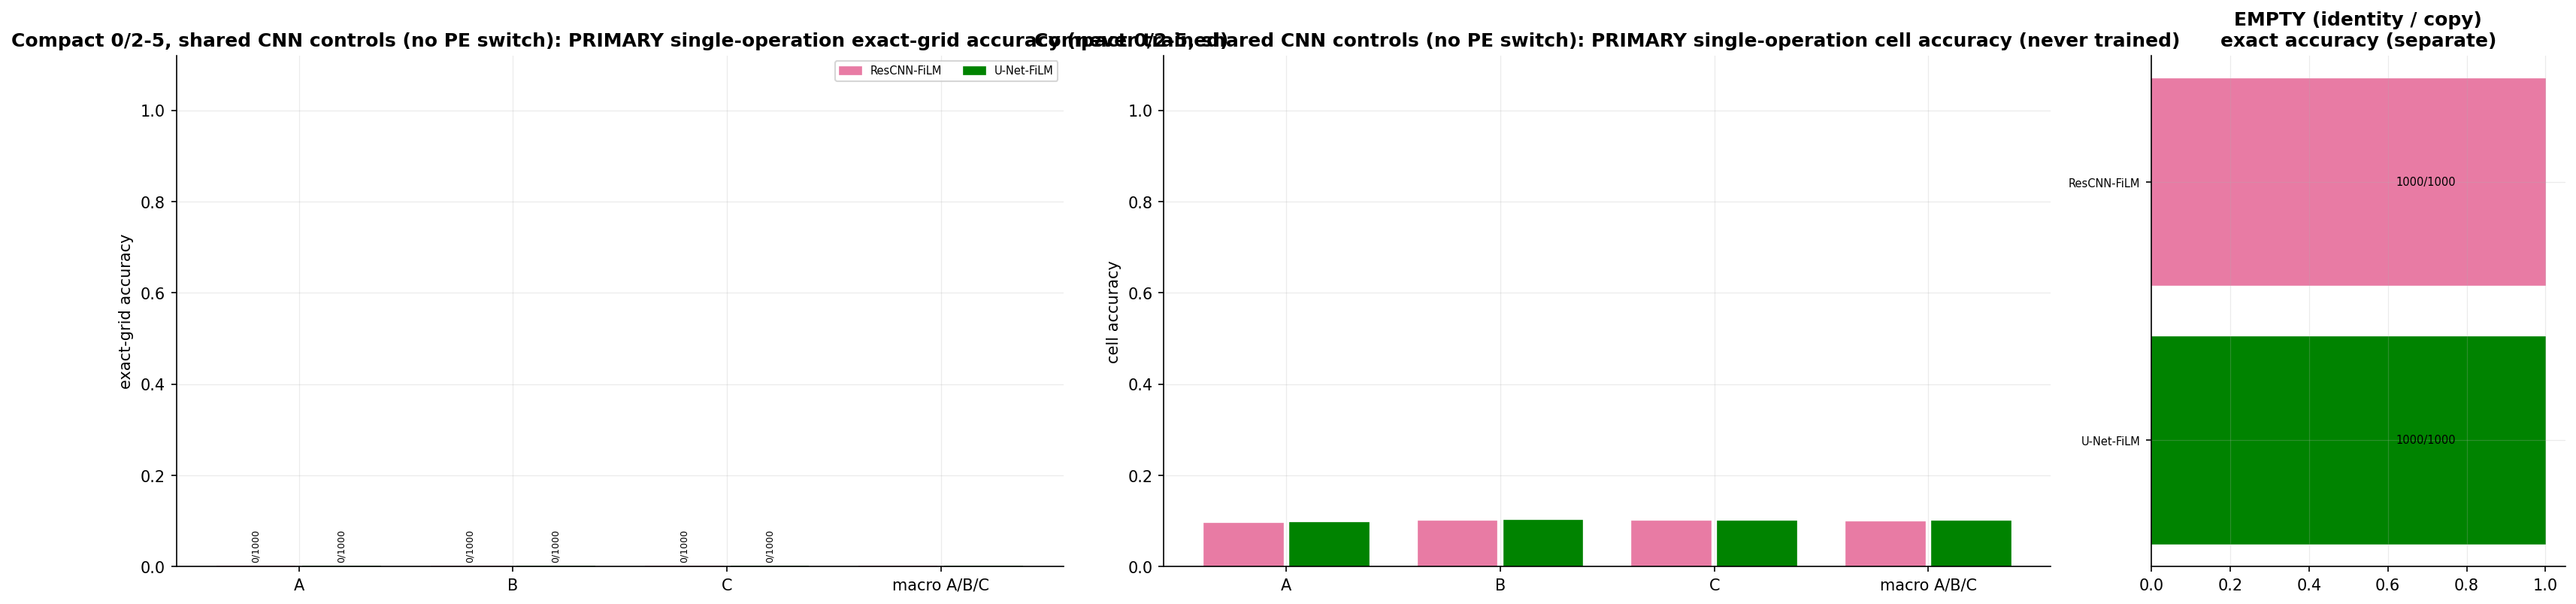

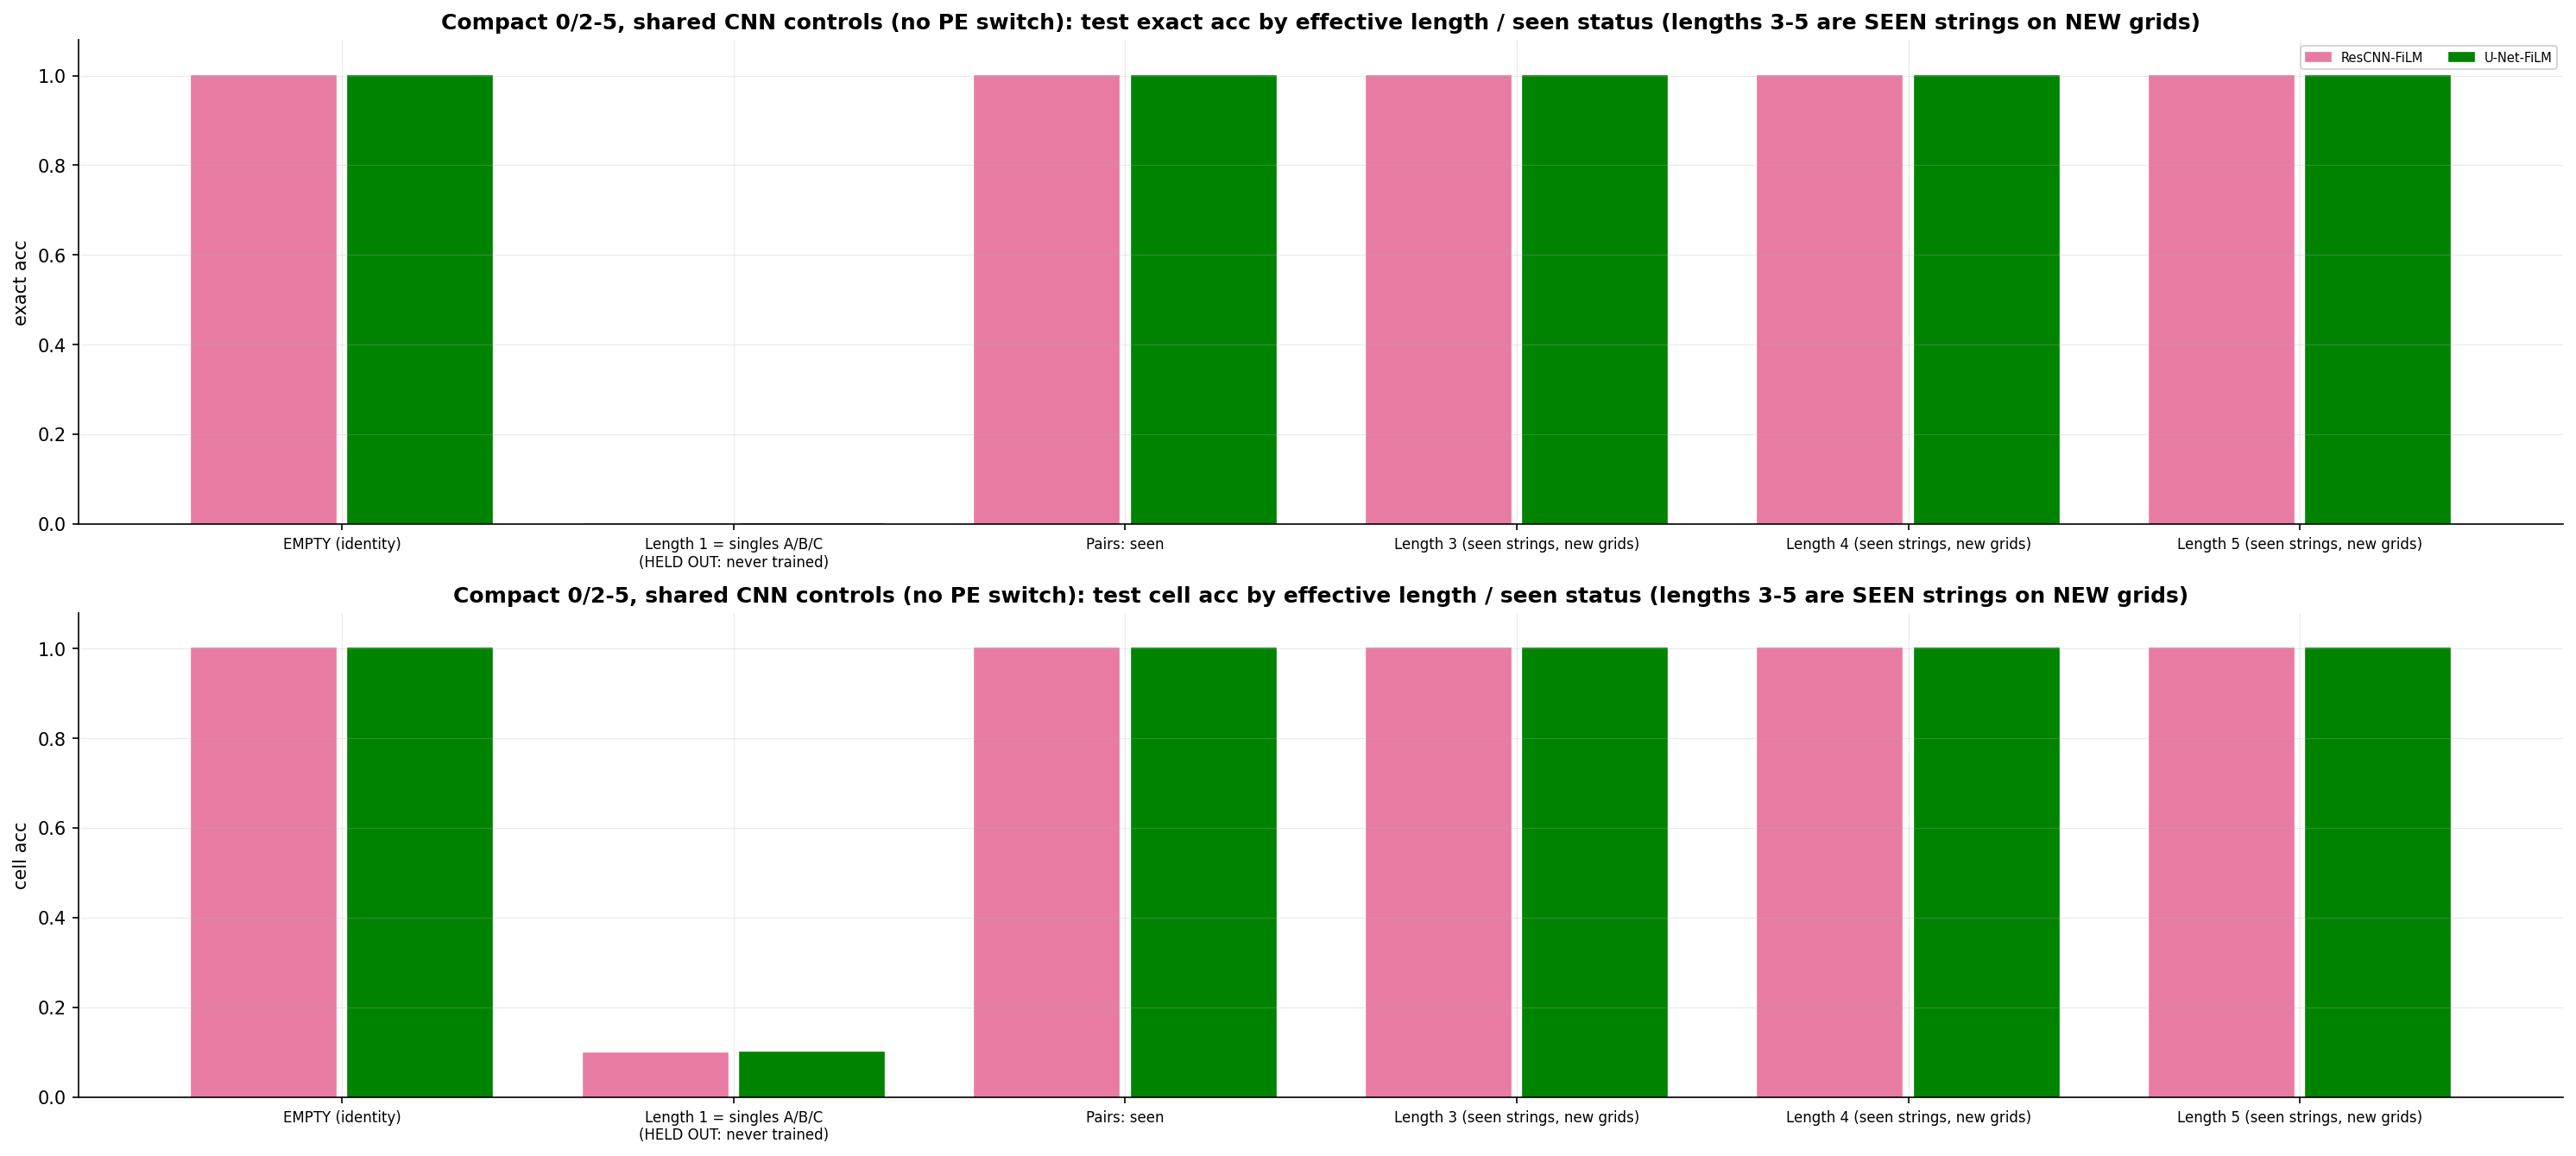

,run,model,condition,status,selected_step,A,B,C,EMPTY,len2,len3,len4,len5,singles_macro_exact
0,rope/transformer_ar,Transformer AR,rope,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,rope/looped_transformer_ar,Looped Transformer AR (tied),rope,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,rope/transformer_encoder,Transformer encoder,rope,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,rope/looped_transformer_encoder,Looped Transformer encoder (tied),rope,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,rope/vit,ViT (2x2 patches),rope,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,rope/looped_vit,Looped ViT (tied baseline),rope,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,rope/trm,TRM-adapted,rope,missing,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,sinusoidal/transformer_ar,Transformer AR,sinusoidal,complete,4500.0,0/1000,0/1000,0/1000,1000/1000,9000/9000,26999/27000,80987/81000,241750/243000,0.0
8,sinusoidal/looped_transformer_ar,Looped Transformer AR (tied),sinusoidal,complete,4750.0,0/1000,0/1000,0/1000,1000/1000,9000/9000,27000/27000,81000/81000,243000/243000,0.0
9,sinusoidal/transformer_encoder,Transformer encoder,sinusoidal,complete,5000.0,0/1000,0/1000,0/1000,1000/1000,9000/9000,27000/27000,81000/81000,242819/243000,0.0


In [9]:
# --- Training/evaluation figures and tables ---------------------------------------------------------------------
from decompositionality.mixed_reports import build_mixed_reports
from decompositionality.compact_reports import combined_table
for cfg_ in (cfg_pe, cfg_cnn):
    build_mixed_reports(cfg_.experiment_dir, cfg_.experiment)
    for name in ["a_training_curves", "a2_validation_by_length", "b1_singles_primary_and_empty",
                 "b2_accuracy_by_length_and_seen_status"]:
        p = cfg_.experiment_dir / "figures" / f"{name}.png"
        if p.exists():
            display(Image(filename=str(p)))
FAMILY_ROOT = cfg_pe.experiment_dir.parent      # COMPACT_ROOT (full) or COMPACT_ROOT/smoke (smoke)
display(combined_table(FAMILY_ROOT))


other PE condition not available yet -> paired PE comparison will be N/A
Artifact inventory:
              experiment                      model                                                                   status
compact_02345_sinusoidal             transformer_ar                                         predictions available (original)
compact_02345_sinusoidal      looped_transformer_ar                                         predictions available (original)
compact_02345_sinusoidal        transformer_encoder                                         predictions available (original)
compact_02345_sinusoidal looped_transformer_encoder                                         predictions available (original)
compact_02345_sinusoidal                        vit                                         predictions available (original)
compact_02345_sinusoidal                 looped_vit                                         predictions available (original)
compact_02345_sinusoidal        

,experiment,model,n_records,n_strings,empty_word_records,duplicate_keys,invalid_records,target_oracle_mismatches,input_manifest_mismatches,decoding
0,compact_02345_sinusoidal,transformer_ar,364000,364,1000,0,0,0,0,AR free-running greedy decoding (eval_summary ...
1,compact_02345_sinusoidal,looped_transformer_ar,364000,364,1000,0,0,0,0,AR free-running greedy decoding (eval_summary ...
2,compact_02345_sinusoidal,transformer_encoder,364000,364,1000,0,0,0,0,parallel prediction (parallel argmax); not aut...
3,compact_02345_sinusoidal,looped_transformer_encoder,364000,364,1000,0,0,0,0,parallel prediction (parallel argmax); not aut...
4,compact_02345_sinusoidal,vit,364000,364,1000,0,0,0,0,parallel prediction (parallel argmax); not aut...
5,compact_02345_sinusoidal,looped_vit,364000,364,1000,0,0,0,0,parallel prediction (parallel argmax); not aut...
6,compact_02345_sinusoidal,trm,364000,364,1000,0,0,0,0,parallel prediction (parallel argmax of final ...
7,compact_02345_cnn,rescnn_film,364000,364,1000,0,0,0,0,parallel prediction (parallel argmax); not aut...
8,compact_02345_cnn,unet_film,364000,364,1000,0,0,0,0,parallel prediction (parallel argmax); not aut...


,experiment,model,string,exact_correct,n,cell_acc,any_exact_group_match_count,dominant_wrong_unique_word,dominant_wrong_unique_share,stable_rule_selected_word,stable_rule_diag_exact_fidelity,argmax_map_diag_cell_fidelity
0,compact_02345_sinusoidal,transformer_ar,EMPTY,1000,1000,1.000000,1000,,0.000,I,1.000,1.000000
1,compact_02345_sinusoidal,transformer_ar,A,0,1000,0.109083,665,AC,0.665,AC,0.656,0.989556
2,compact_02345_sinusoidal,transformer_ar,B,0,1000,0.190528,3,BC,0.003,BC,0.002,0.979333
3,compact_02345_sinusoidal,transformer_ar,C,0,1000,0.099111,1000,I,1.000,I,1.000,1.000000
40,compact_02345_sinusoidal,looped_transformer_ar,EMPTY,1000,1000,1.000000,1000,,0.000,I,1.000,1.000000
41,compact_02345_sinusoidal,looped_transformer_ar,A,0,1000,0.500722,0,,0.000,AC,0.000,0.900944
42,compact_02345_sinusoidal,looped_transformer_ar,B,0,1000,0.205667,0,,0.000,BC,0.000,0.939667
43,compact_02345_sinusoidal,looped_transformer_ar,C,0,1000,0.100306,460,I,0.460,I,0.462,0.980944
80,compact_02345_sinusoidal,transformer_encoder,EMPTY,1000,1000,1.000000,1000,,0.000,I,1.000,1.000000
81,compact_02345_sinusoidal,transformer_encoder,A,0,1000,0.099000,1000,AC,1.000,AC,1.000,1.000000


,experiment,model,population,hypothesis_type,population_records,population_wrong_records,population_any_legal_match_records,applicable_records,eligible_records,matched_unique_records,conditional_rate (matched/eligible),unconditional_coverage (matched/population),truth_equivalent_strings
0,compact_02345_sinusoidal,transformer_ar,singletons A/B/C (never trained),identity,3000,3000,1668,3000,3000,1000,0.333333,0.333333,0
1,compact_02345_sinusoidal,transformer_ar,singletons A/B/C (never trained),first_op,3000,3000,1668,3000,0,0,NaN,0.000000,3
2,compact_02345_sinusoidal,transformer_ar,singletons A/B/C (never trained),last_op,3000,3000,1668,3000,0,0,NaN,0.000000,3
3,compact_02345_sinusoidal,transformer_ar,singletons A/B/C (never trained),first_and_last,3000,3000,1668,3000,3000,1000,0.333333,0.333333,0
4,compact_02345_sinusoidal,transformer_ar,singletons A/B/C (never trained),first_two,3000,3000,1668,0,0,0,NaN,0.000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
457,compact_02345_cnn,unet_film,singletons A/B/C (never trained),dedupe_global,3000,3000,2118,0,0,0,NaN,0.000000,0
458,compact_02345_cnn,unet_film,singletons A/B/C (never trained),duplicate_single,3000,3000,2118,3000,3000,1000,0.333333,0.333333,0
459,compact_02345_cnn,unet_film,singletons A/B/C (never trained),X_then_C,3000,3000,2118,3000,3000,2118,0.706000,0.706000,0
460,compact_02345_cnn,unet_film,singletons A/B/C (never trained),C_then_X,3000,3000,2118,3000,3000,1000,0.333333,0.333333,0


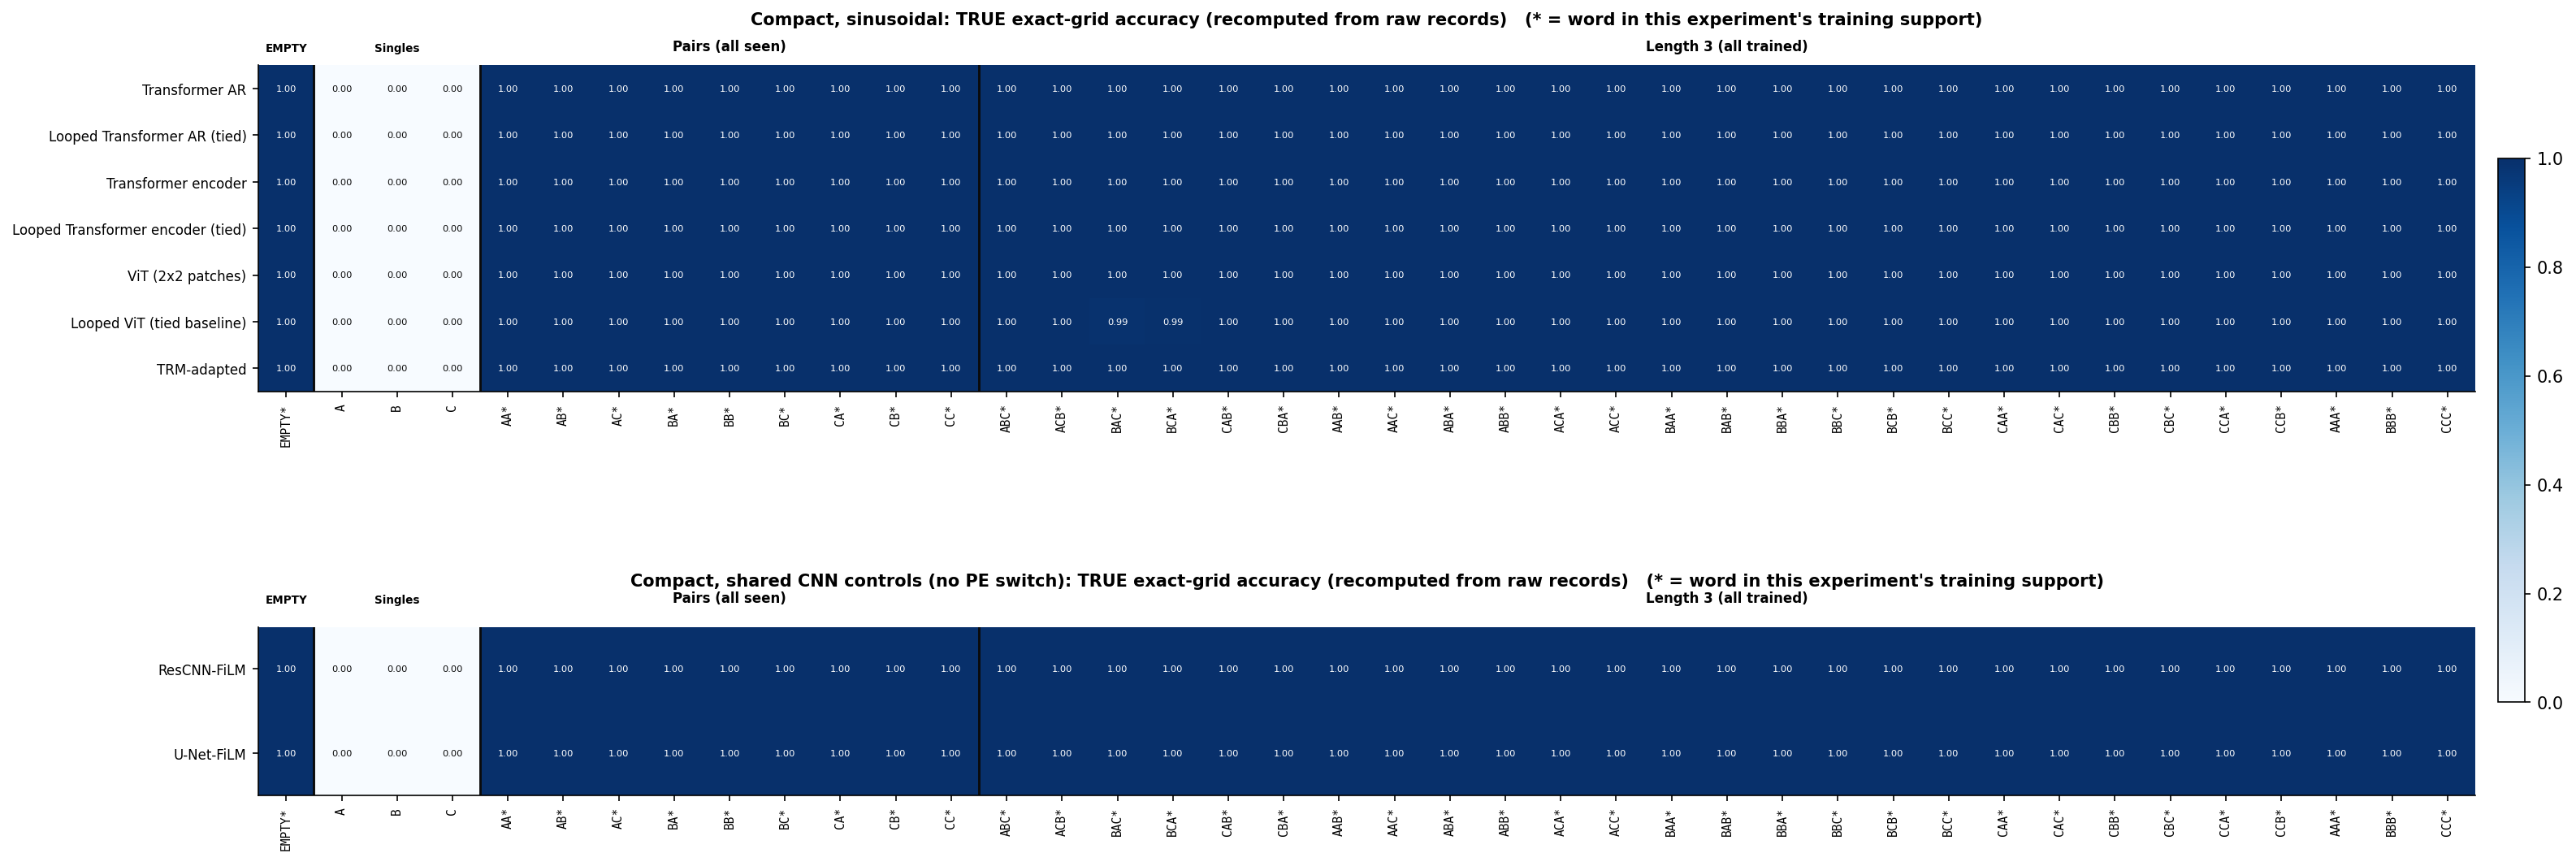

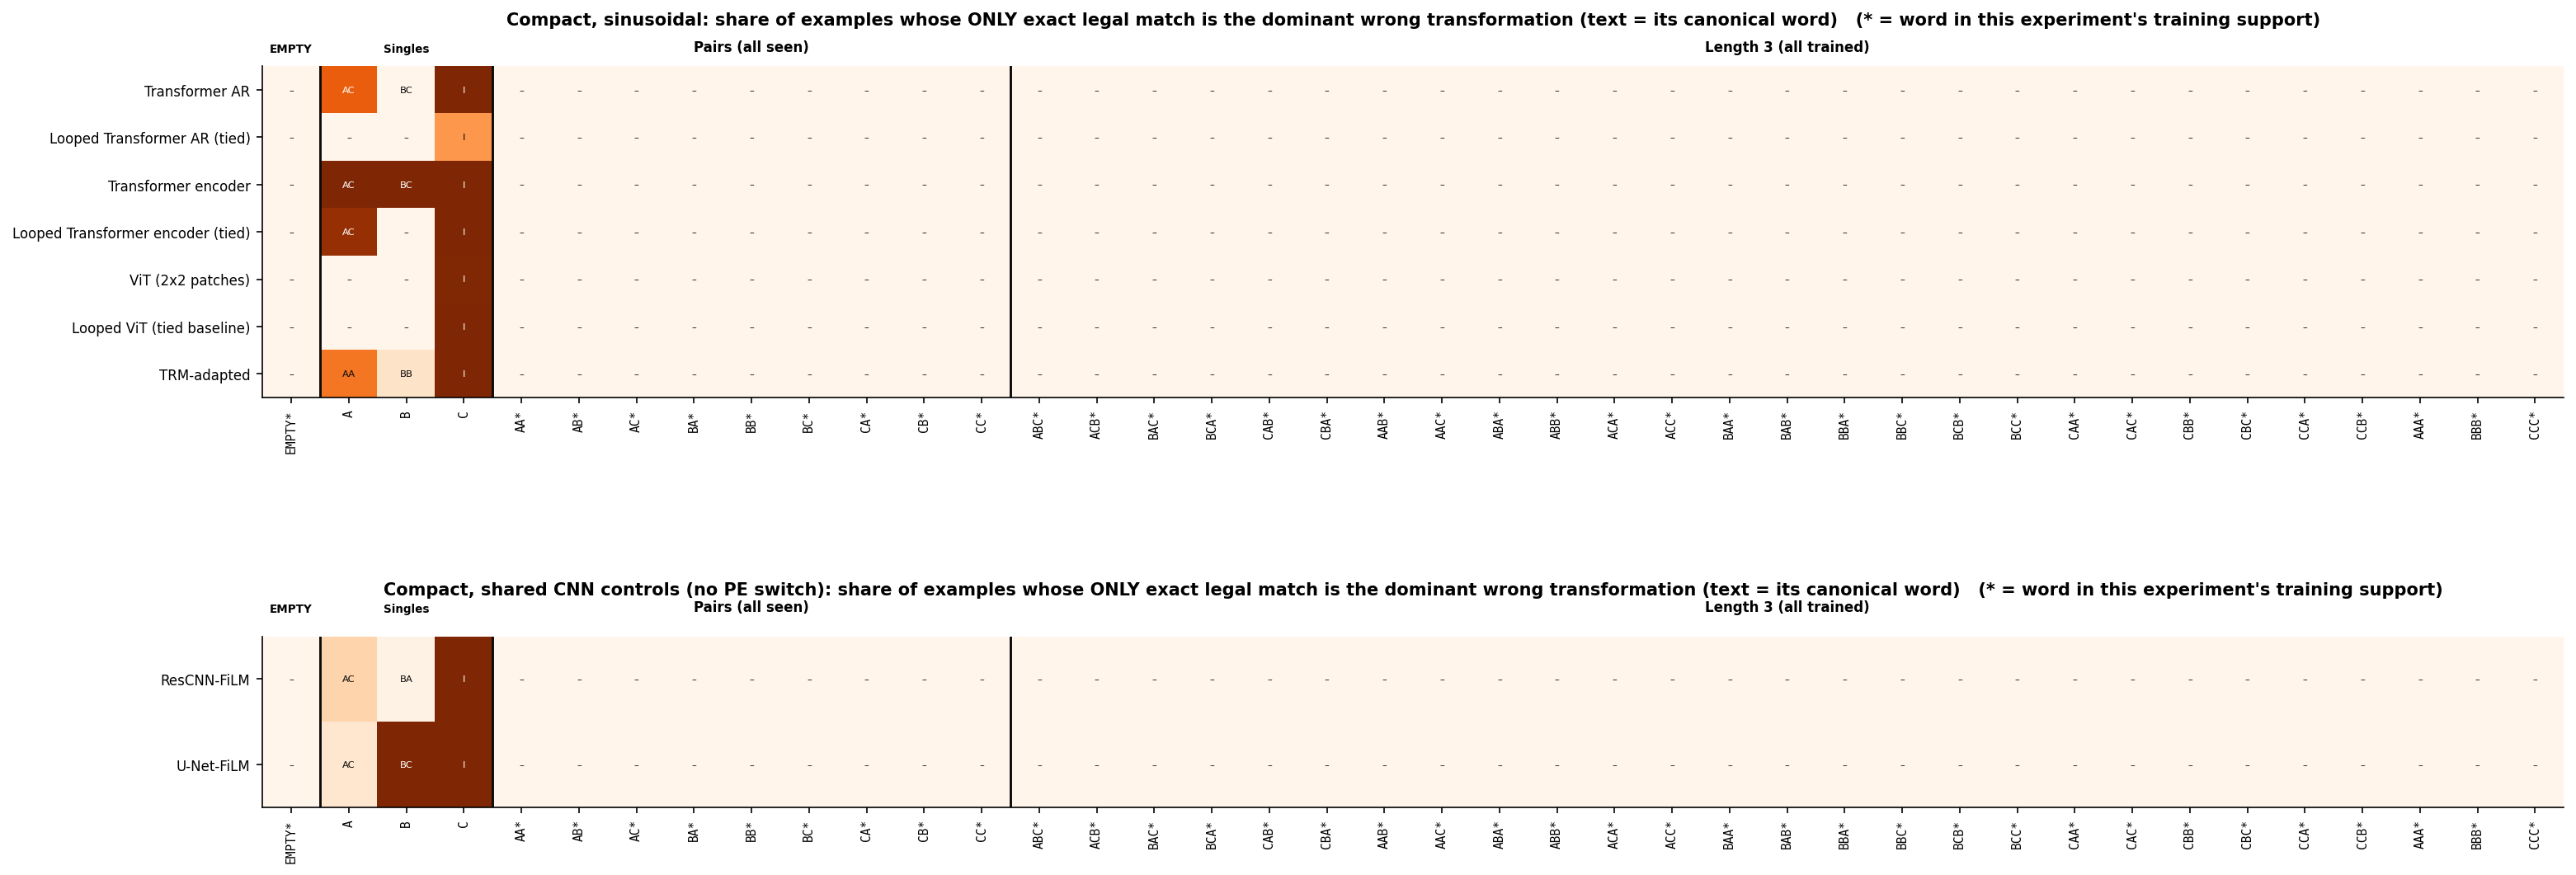

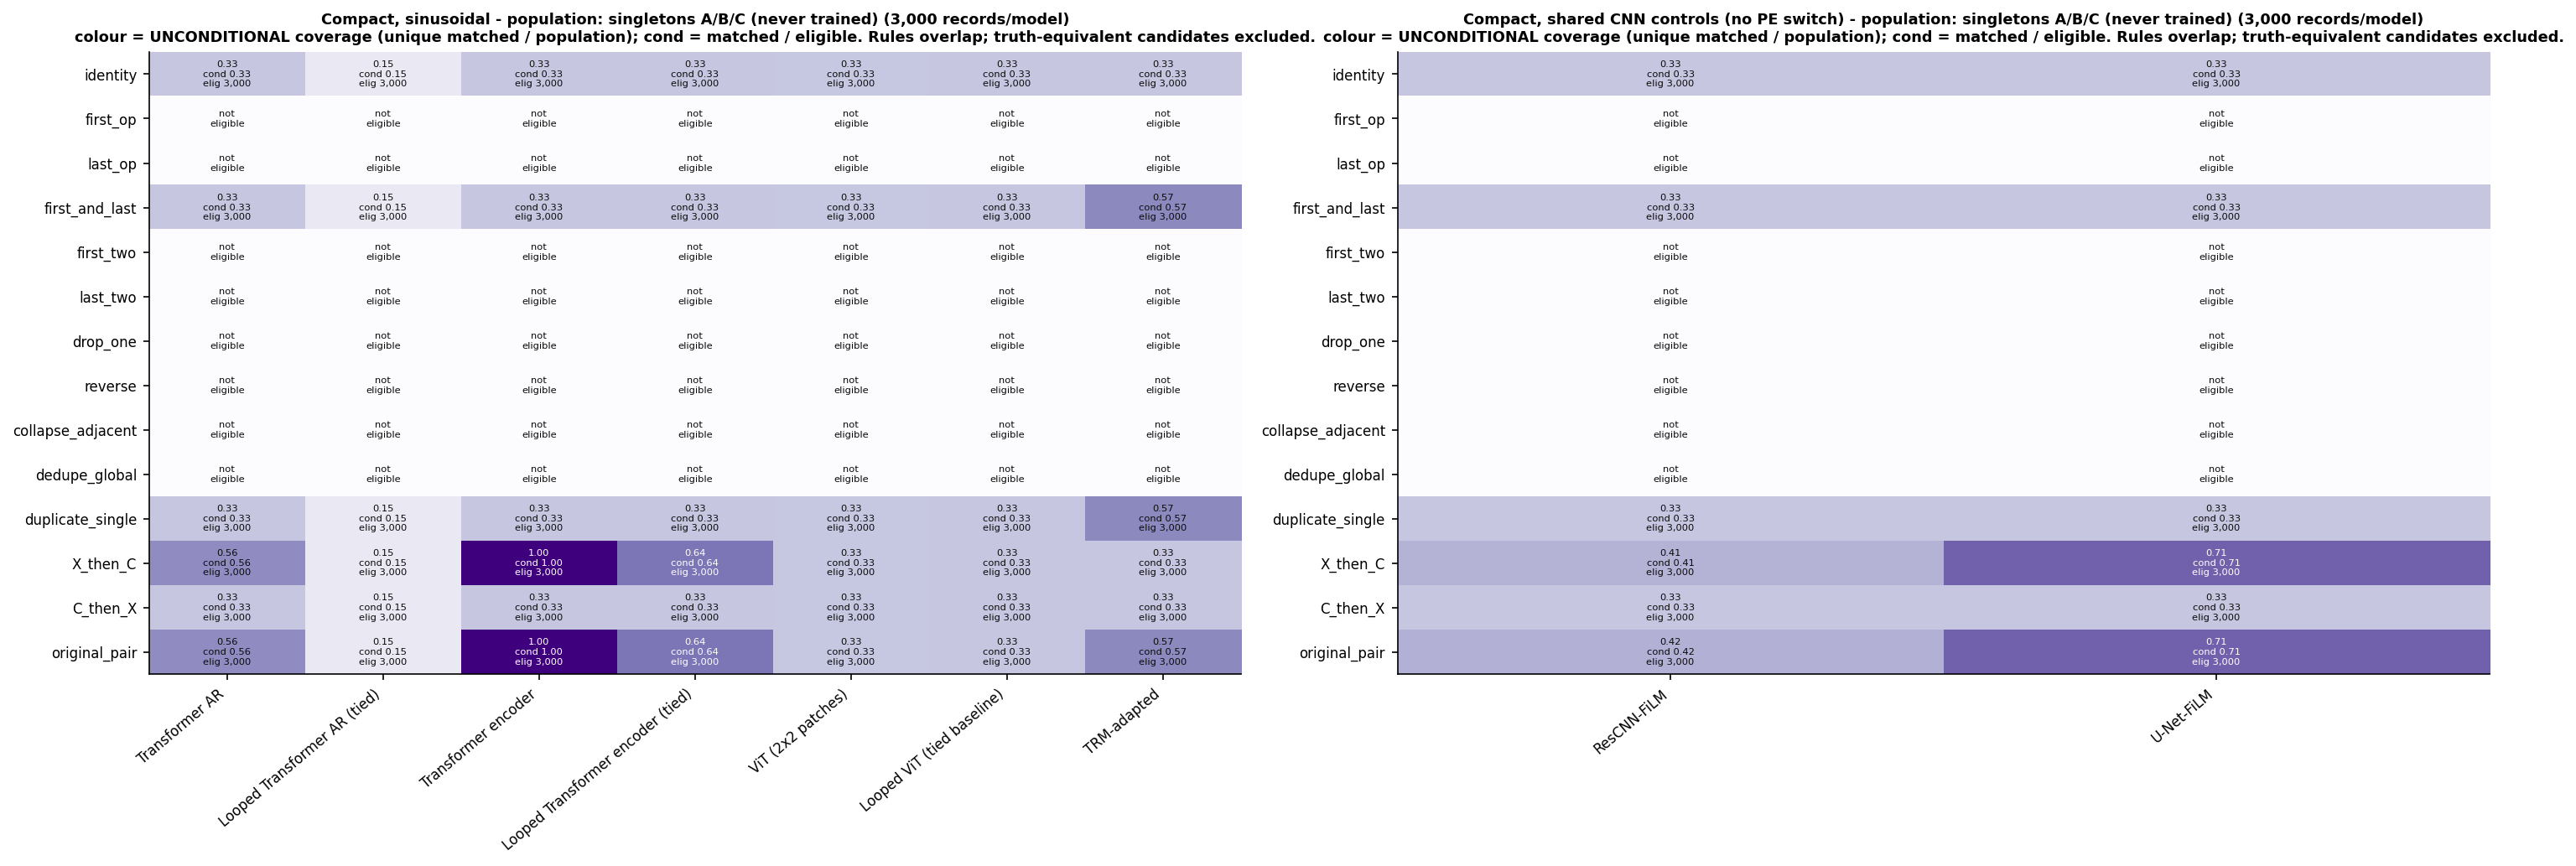

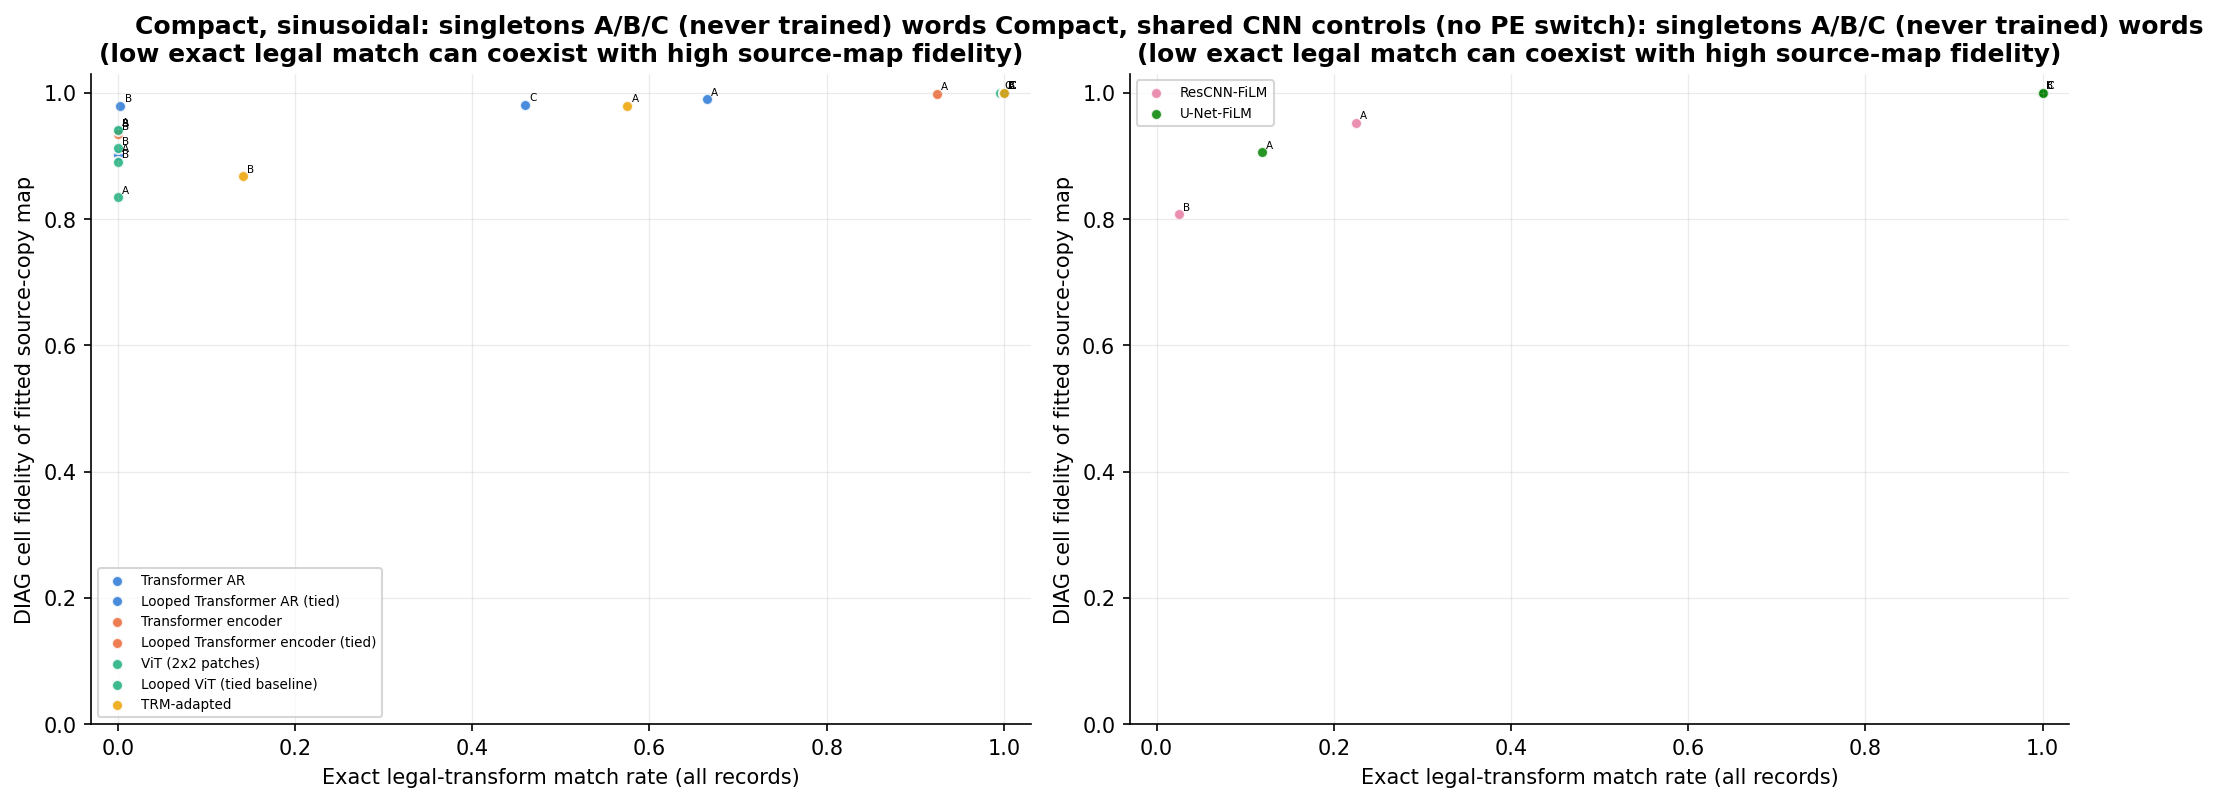

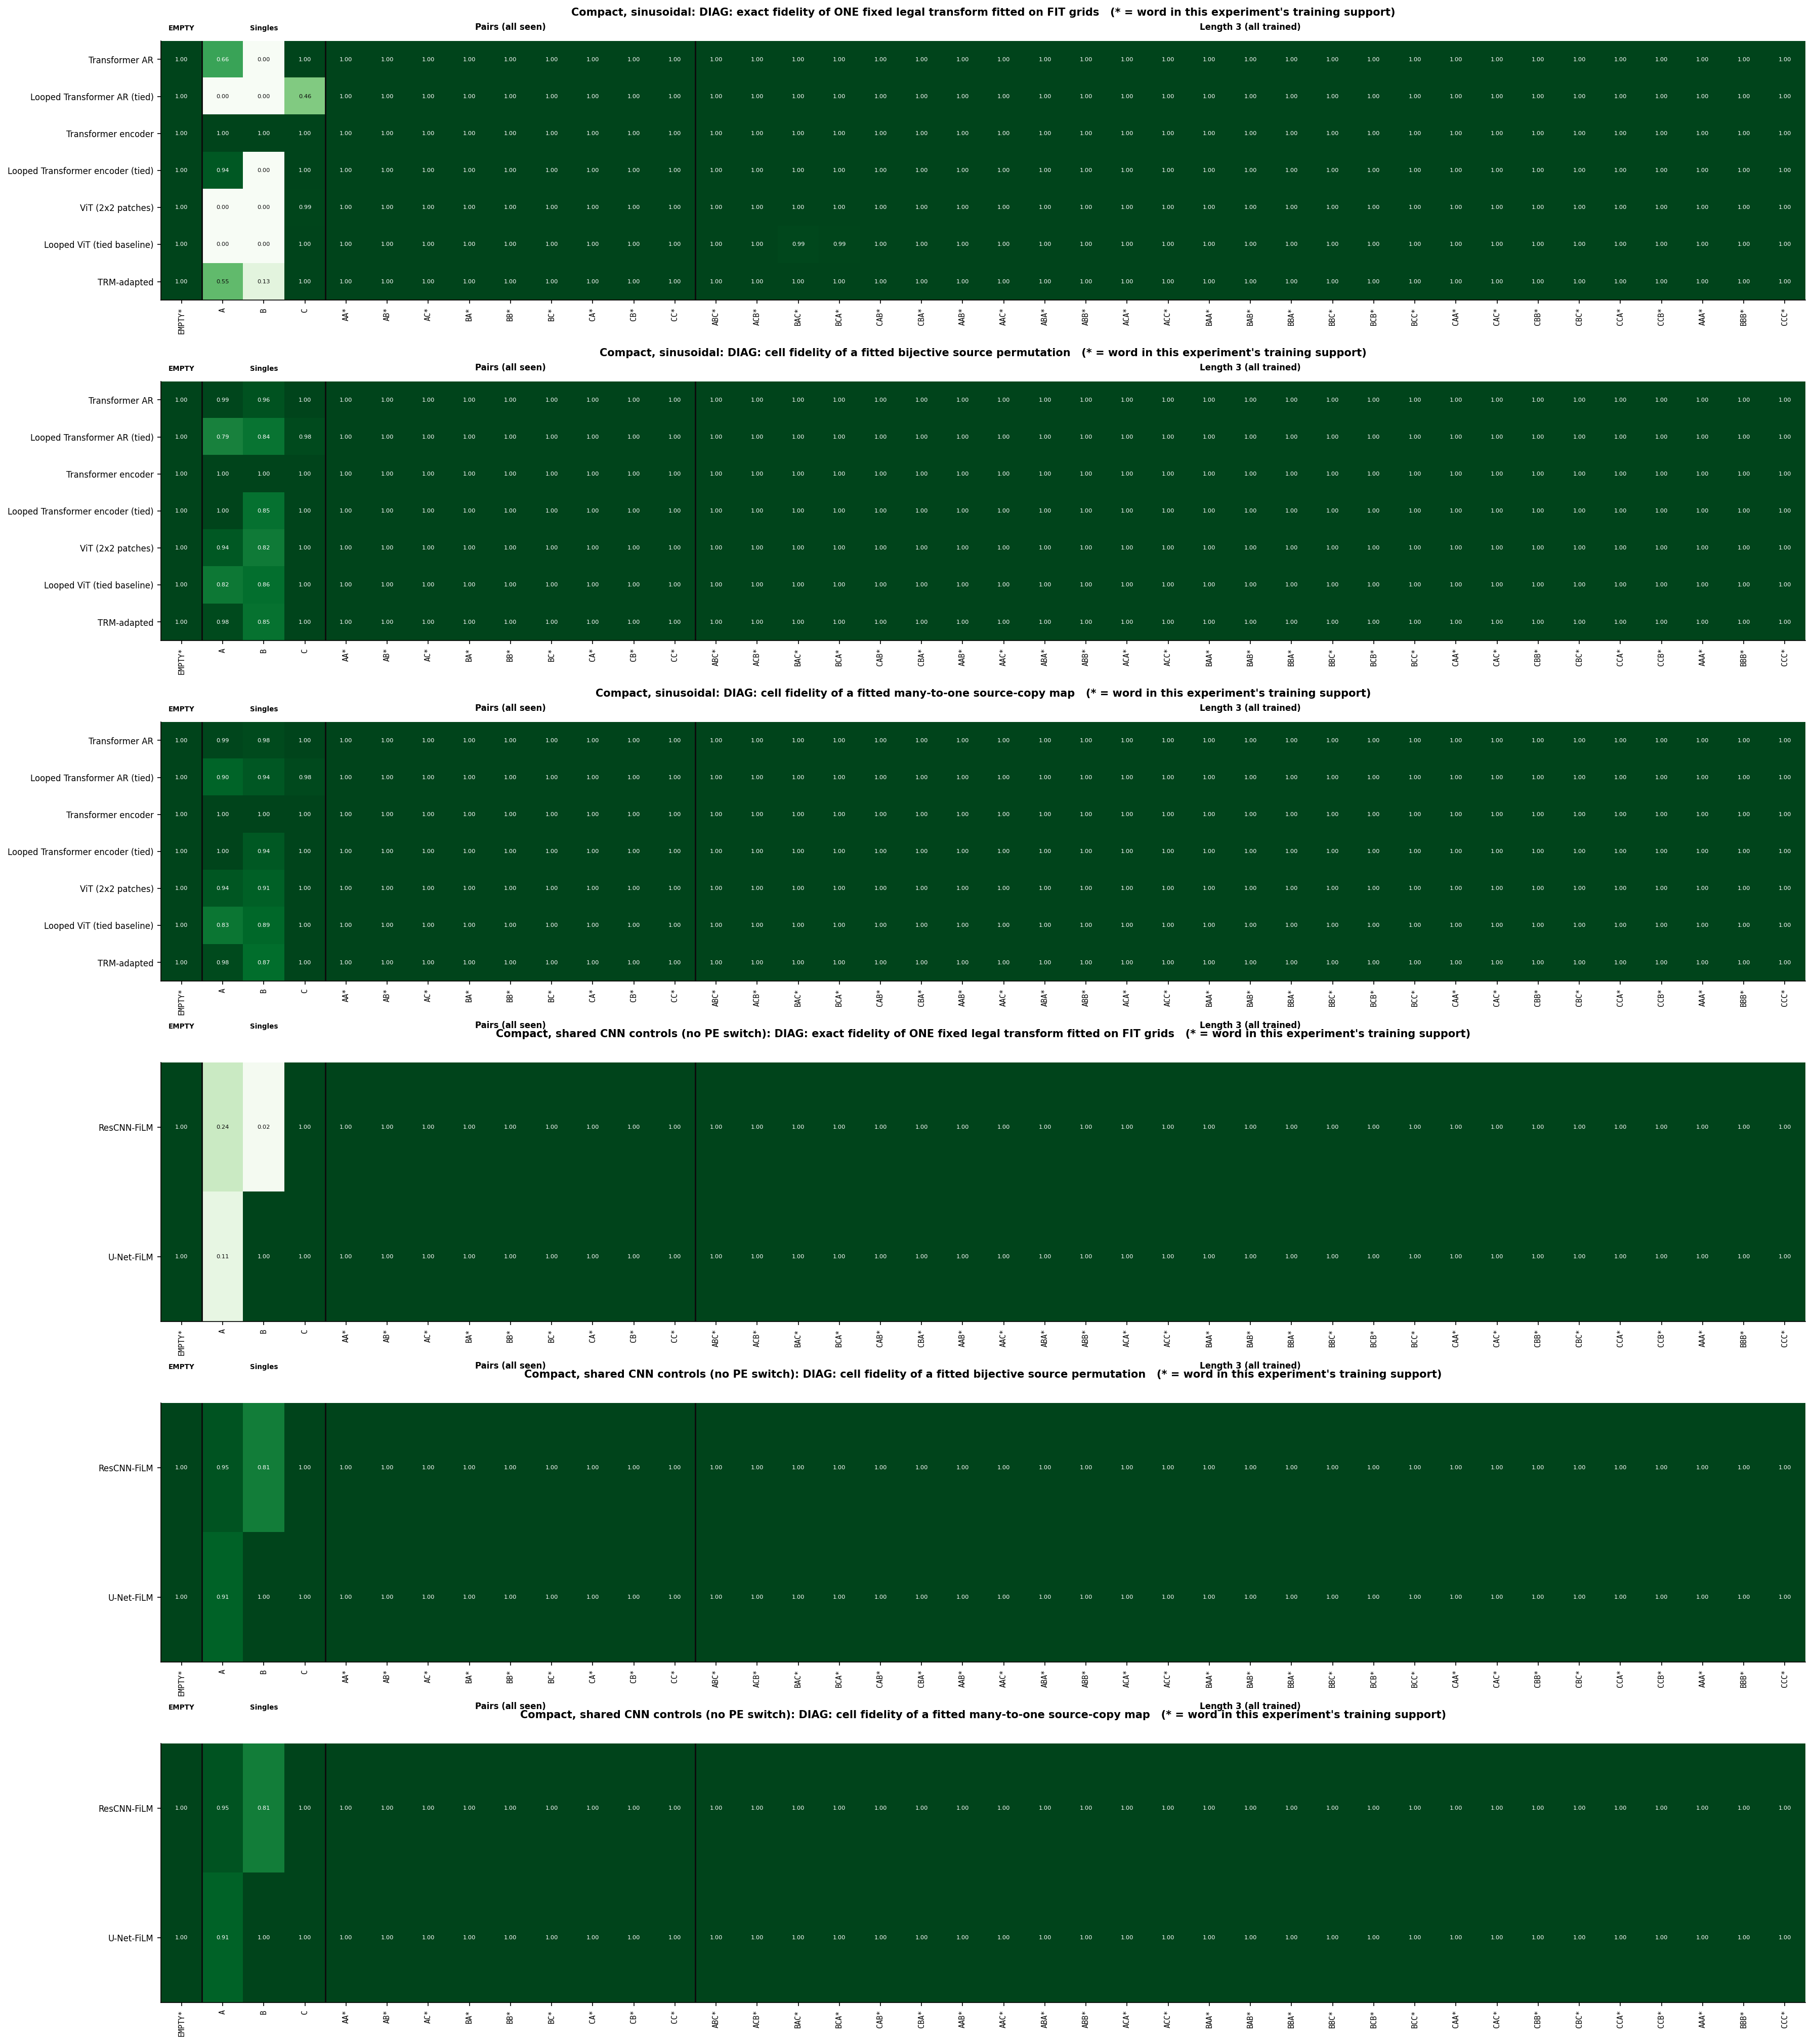

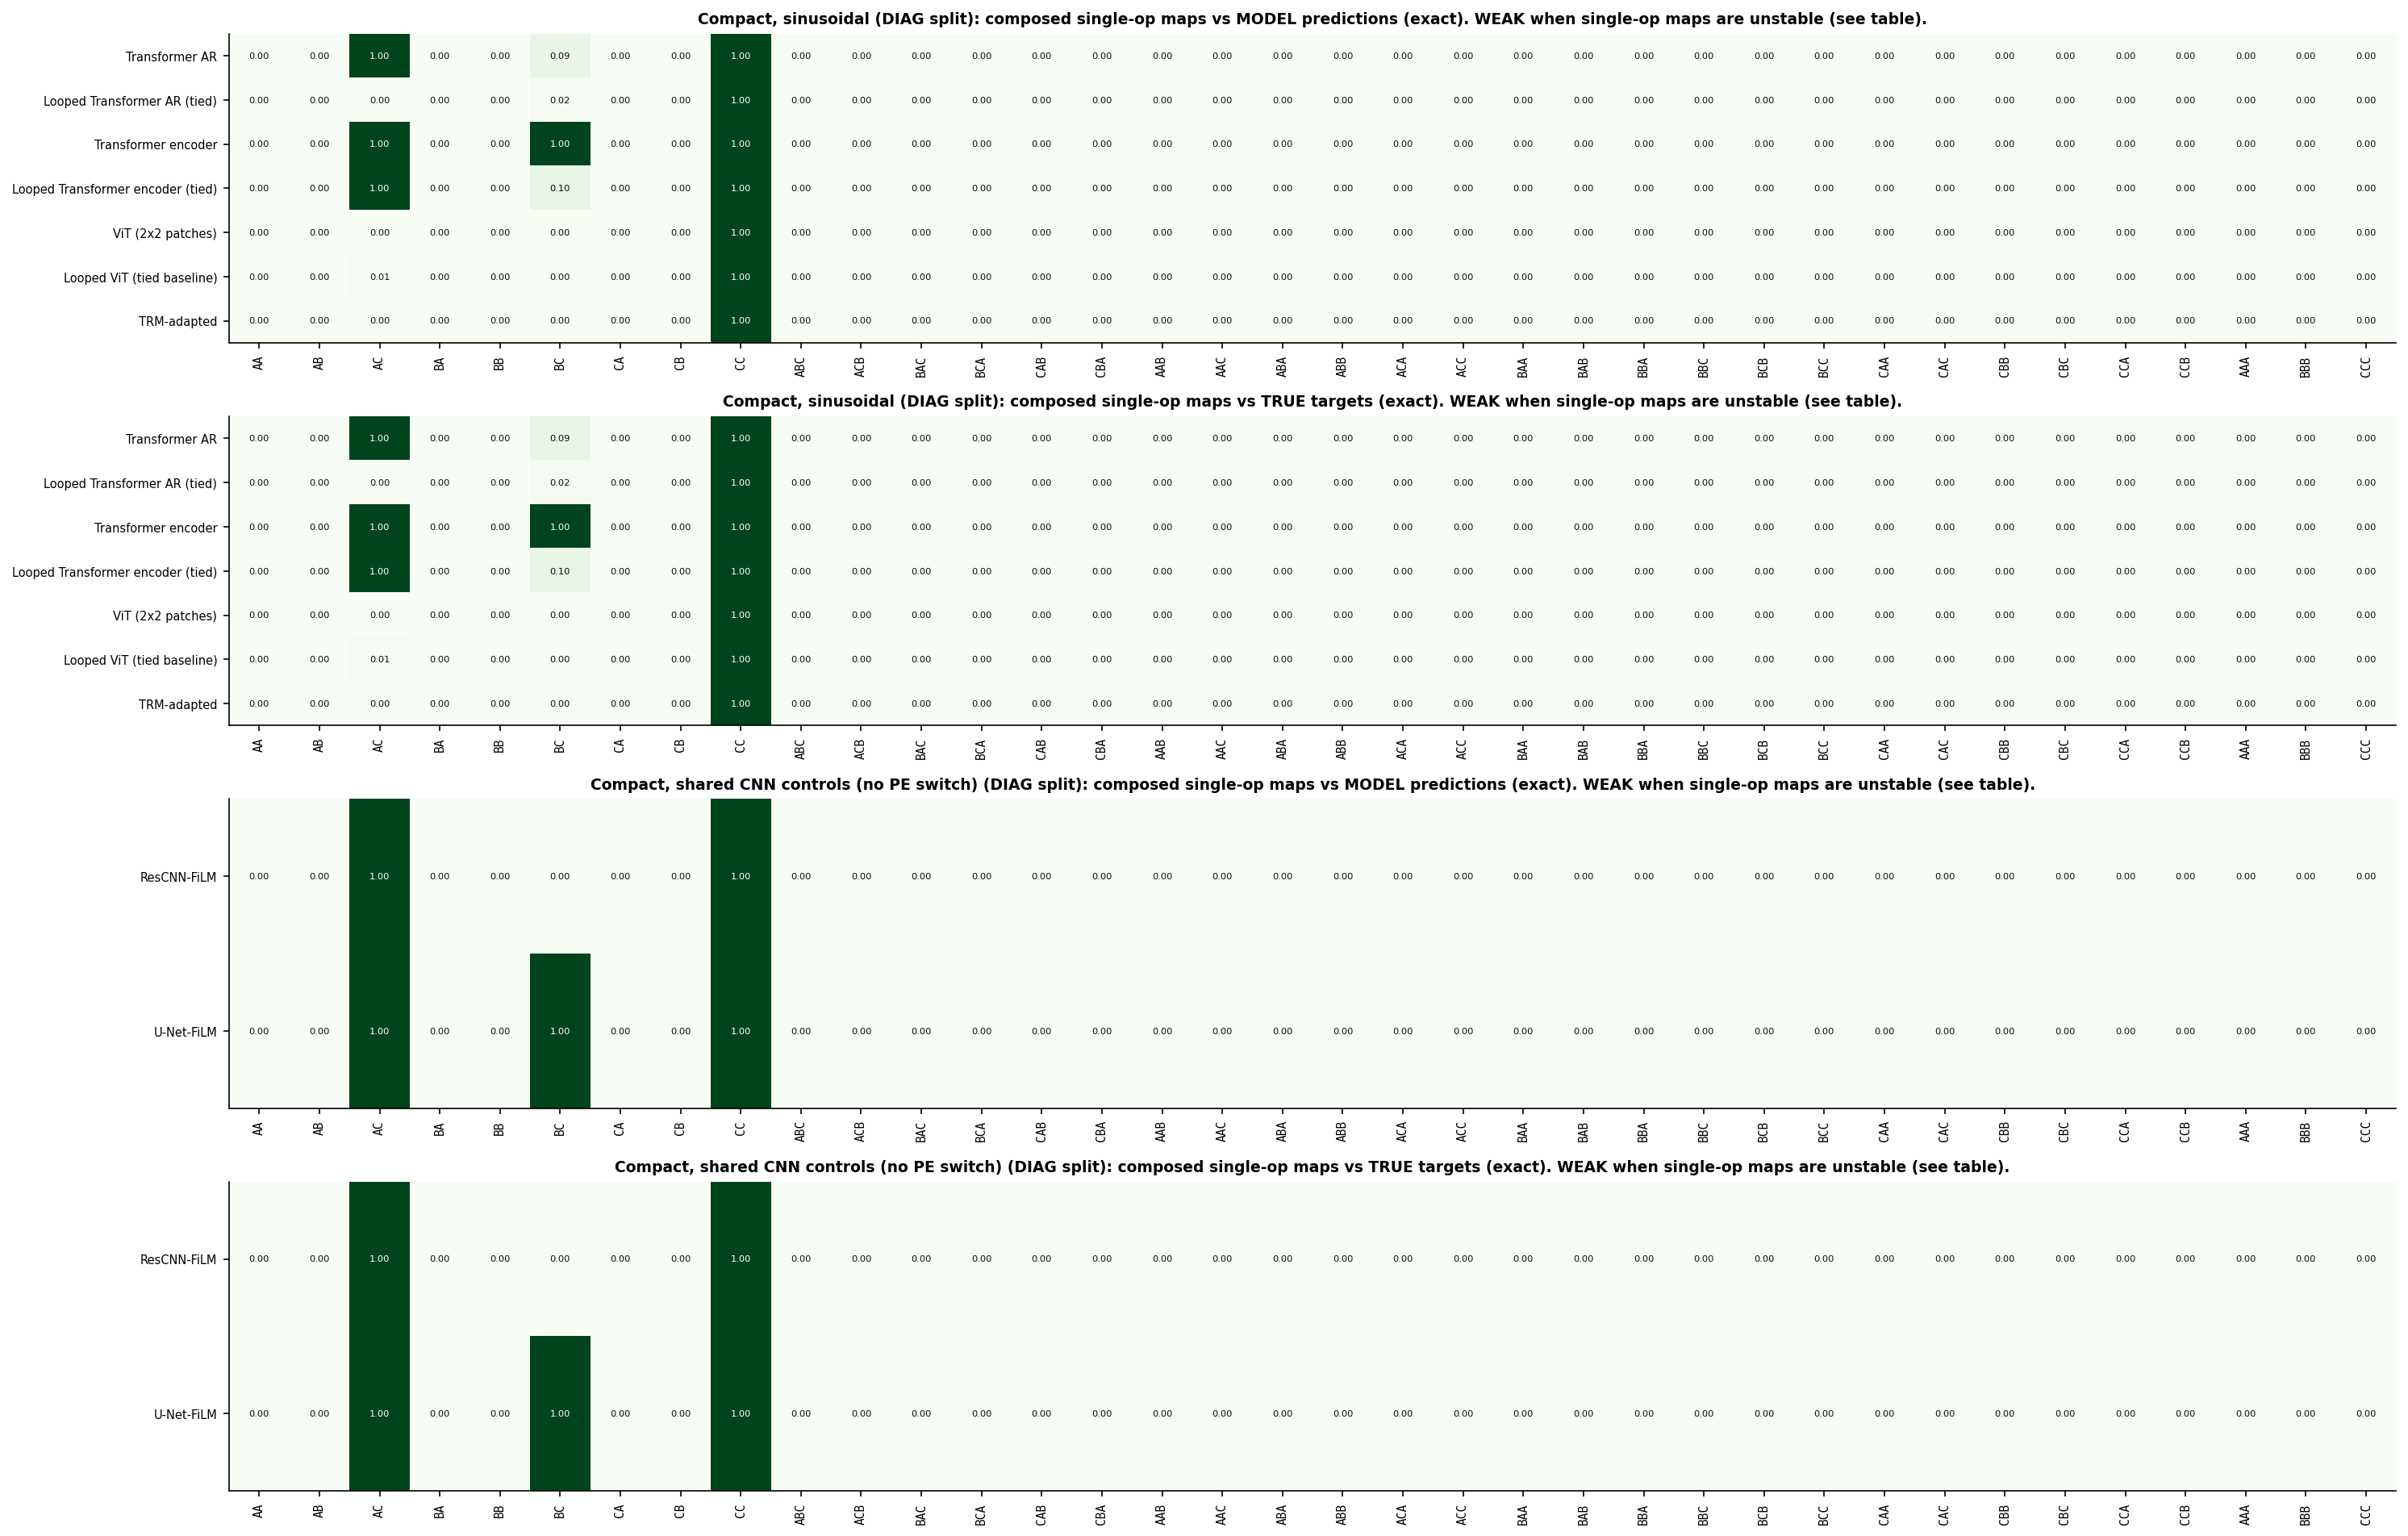

In [10]:
# --- Diagnostics on saved predictions (this PE + shared CNNs + the other PE if available; read-only) -----------
from decompositionality.diagnosis.runner import DiagnosticsConfig, run_diagnostics
from decompositionality.diagnosis.spec import get_spec
other = "compact_02345_sinusoidal" if PE == "rope" else "compact_02345_rope"
dirs = {cfg_pe.experiment: str(cfg_pe.experiment_dir), cfg_cnn.experiment: str(cfg_cnn.experiment_dir)}
other_dir = cfg_pe.experiment_dir.parent / M.COMPACT_DIRS[other]
if (other_dir / "eval").exists():
    dirs[other] = str(other_dir); print("including the other PE condition (read-only):", other_dir)
else:
    print("other PE condition not available yet -> paired PE comparison will be N/A")
dcfg = DiagnosticsConfig(experiment_dirs=dirs, output_dir=str(cfg_pe.experiment_dir / "diagnostics"),
                         models=ATTN_MODELS + CNN_CONTROLS, chunk_size=ANALYSIS_CHUNK_SIZE, use_cache=USE_ANALYSIS_CACHE,
                         spec="compact", analysis_words=get_spec("compact").common_panel,
                         example_strings=["EMPTY", "A", "B", "C", "AB", "ABC"])
R = run_diagnostics(dcfg)
DFIG = pathlib.Path(R["output_dir"]) / "figures"
def show(prefix):
    for p in sorted(DFIG.glob(prefix + "*.png")):
        display(Image(filename=str(p)))
display(R["audit"][["experiment", "model", "n_records", "n_strings", "empty_word_records", "duplicate_keys",
                    "invalid_records", "target_oracle_mismatches", "input_manifest_mismatches", "decoding"]])
sing = R["per_string"][R["per_string"].group.isin(["singles", "EMPTY"])]
display(sing[["experiment", "model", "string", "exact_correct", "n", "cell_acc", "any_exact_group_match_count",
              "dominant_wrong_unique_word", "dominant_wrong_unique_share", "stable_rule_selected_word",
              "stable_rule_diag_exact_fidelity", "argmax_map_diag_cell_fidelity"]])
hs = R["hypothesis_summary"]
display(hs[hs.population.str.startswith("singletons")])
show("01_true"); show("04_dominant"); show("05_hypothesis"); show("13_exact"); show("08_stable"); show("09_composition")


In [11]:
# --- Paired RoPE minus sinusoidal on identical test examples (needs both notebooks; N/A otherwise) -------------
from decompositionality.compact_reports import paired_pe_comparison
pc = paired_pe_comparison(cfg_pe.experiment_dir.parent)
if pc is not None:
    display(pc[pc.word_or_group.isin(["A", "B", "C"]) | pc.word_or_group.str.startswith("[group]")])
    cmp_dir = cfg_pe.experiment_dir.parent / "comparisons"
    display(Image(filename=str(cmp_dir / "paired_rope_minus_sinusoidal.png")))
    show("11_paired")


Paired RoPE-vs-sinusoidal comparison unavailable: both conditions must have completed evaluations (run the other notebook; this notebook does not require it).


In [12]:
# --- Export (no checkpoints, chunks or caches) --------------------------------------------------------------------
from decompositionality.mixed_reports import make_compact_archive
for cfg_ in (cfg_pe, cfg_cnn):
    make_compact_archive(cfg_.experiment_dir)
display(Markdown(pathlib.Path(R["report_path"]).read_text()))


Compact archive: /content/drive/MyDrive/decompositionality_results/compact_02345_pe/sinusoidal/results_sinusoidal.zip (29.6 MiB)
Compact archive: /content/drive/MyDrive/decompositionality_results/compact_02345_pe/shared_cnn/results_shared_cnn.zip (6.7 MiB)


# Generalization-failure diagnostics (compact family; analysis generalization-failure-diagnostics-v3)

Generated automatically from the saved prediction artifacts listed below. It describes model BEHAVIOUR on test inputs. Compatibility with an explanation does not establish internal representations or causality; one training seed only.

Definitions: a fitted fixed rule is **stable** if its DIAG exact fidelity >= 0.95; a source map is **adequate** if its DIAG cell fidelity >= 0.9. DIAG = disjoint half of the base grids not used for fitting.

## 1. Data coverage and provenance

| experiment | model | status |
|---|---|---|
| compact_02345_sinusoidal | transformer_ar | predictions available (original) |
| compact_02345_sinusoidal | looped_transformer_ar | predictions available (original) |
| compact_02345_sinusoidal | transformer_encoder | predictions available (original) |
| compact_02345_sinusoidal | looped_transformer_encoder | predictions available (original) |
| compact_02345_sinusoidal | vit | predictions available (original) |
| compact_02345_sinusoidal | looped_vit | predictions available (original) |
| compact_02345_sinusoidal | trm | predictions available (original) |
| compact_02345_sinusoidal | rescnn_film | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_sinusoidal | unet_film | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_cnn | transformer_ar | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_cnn | looped_transformer_ar | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_cnn | transformer_encoder | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_cnn | looped_transformer_encoder | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_cnn | vit | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_cnn | looped_vit | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_cnn | trm | MISSING: no predictions and no usable checkpoint -> analysis unavailable |
| compact_02345_cnn | rescnn_film | predictions available (original) |
| compact_02345_cnn | unet_film | predictions available (original) |

### Audit

| experiment | model | source | n_records | n_strings | selected_step | code_commit_at_eval | decoding | duplicate_keys | invalid_records | target_oracle_mismatches | input_manifest_mismatches | attribution_blocked |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| compact_02345_sinusoidal | transformer_ar | original | 364000 | 364 | 4500 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| compact_02345_sinusoidal | looped_transformer_ar | original | 364000 | 364 | 4750 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | AR free-running greedy decoding (eval_summary + TransformerAR.predict code path) | 0 | 0 | 0 | 0 | False |
| compact_02345_sinusoidal | transformer_encoder | original | 364000 | 364 | 5000 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_sinusoidal | looped_transformer_encoder | original | 364000 | 364 | 5000 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_sinusoidal | vit | original | 364000 | 364 | 5000 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_sinusoidal | looped_vit | original | 364000 | 364 | 5000 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_sinusoidal | trm | original | 364000 | 364 | 5000 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax of final refinement); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_cnn | rescnn_film | original | 364000 | 364 | 4750 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |
| compact_02345_cnn | unet_film | original | 364000 | 364 | 5000 | 4e5b1858d792d7b3c7df14011c5127adff7e12c8 | parallel prediction (parallel argmax); not autoregressive | 0 | 0 | 0 | 0 | False |


- Stored targets re-derived with the independent oracle for **3,276,000** records; mismatches: **0**.
- Test manifests identical across loaded experiments: **True**.
- A synthetic perfect-oracle predictor passed through the same loader/metric code scores 100% on all 364 words (checks the analysis path, not any checkpoint's forward pass).

## 2. Verified observations (recomputed from raw records)

Integer exact successes / records are shown; rates have 4 decimals (e.g. 8998/9000 = 0.9998 is NOT 1). Columns prefixed DIAG use only the diagnostic half of the base grids. N/A = empty category.

| experiment | model | group | exact_correct | n_records | true_exact_acc | true_cell_acc | any_legal_match_records | any_exact_legal_match | exact_set_includes_original_pair | DIAG stable_rule_exact_fidelity | DIAG argmax_map_cell_fidelity | DIAG bijective_perm_cell_fidelity |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| compact_02345_sinusoidal | Transformer AR | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Transformer AR | singles | 0 | 3000 | 0.0000 | 0.1329 | 1668 | 0.5560 | 0.5560 | 0.5527 | 0.9896 | 0.9816 |
| compact_02345_sinusoidal | Transformer AR | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Transformer AR | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Transformer AR | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Transformer AR | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Looped Transformer AR (tied) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped Transformer AR (tied) | singles | 0 | 3000 | 0.0000 | 0.2689 | 460 | 0.1533 | 0.1533 | 0.1540 | 0.9405 | 0.8690 |
| compact_02345_sinusoidal | Looped Transformer AR (tied) | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped Transformer AR (tied) | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped Transformer AR (tied) | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Looped Transformer AR (tied) | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Transformer encoder | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Transformer encoder | singles | 0 | 3000 | 0.0000 | 0.0999 | 3000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Transformer encoder | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Transformer encoder | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Transformer encoder | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Transformer encoder | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Looped Transformer encoder (tied) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped Transformer encoder (tied) | singles | 0 | 3000 | 0.0000 | 0.1034 | 1924 | 0.6413 | 0.6413 | 0.6453 | 0.9777 | 0.9500 |
| compact_02345_sinusoidal | Looped Transformer encoder (tied) | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped Transformer encoder (tied) | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped Transformer encoder (tied) | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Looped Transformer encoder (tied) | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | ViT (2x2 patches) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | ViT (2x2 patches) | singles | 0 | 3000 | 0.0000 | 0.0985 | 996 | 0.3320 | 0.3320 | 0.3313 | 0.9511 | 0.9174 |
| compact_02345_sinusoidal | ViT (2x2 patches) | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | ViT (2x2 patches) | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | ViT (2x2 patches) | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | ViT (2x2 patches) | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Looped ViT (tied baseline) | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped ViT (tied baseline) | singles | 0 | 3000 | 0.0000 | 0.0996 | 1000 | 0.3333 | 0.3333 | 0.3333 | 0.9081 | 0.8946 |
| compact_02345_sinusoidal | Looped ViT (tied baseline) | pairs_seen | 8999 | 9000 | 0.9999 | 1.0000 | 8999 | 0.9999 | 0.9999 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped ViT (tied baseline) | len3_seen | 26976 | 27000 | 0.9991 | 1.0000 | 26976 | 0.9991 | 0.0000 | 0.9992 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | Looped ViT (tied baseline) | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | Looped ViT (tied baseline) | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | TRM-adapted | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | TRM-adapted | singles | 0 | 3000 | 0.0000 | 0.1036 | 1716 | 0.5720 | 0.5720 | 0.5593 | 0.9489 | 0.9428 |
| compact_02345_sinusoidal | TRM-adapted | pairs_seen | 8999 | 9000 | 0.9999 | 1.0000 | 8999 | 0.9999 | 0.9999 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | TRM-adapted | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| compact_02345_sinusoidal | TRM-adapted | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_sinusoidal | TRM-adapted | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_cnn | ResCNN-FiLM | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | ResCNN-FiLM | singles | 0 | 3000 | 0.0000 | 0.0979 | 1250 | 0.4167 | 0.4167 | 0.4200 | 0.9198 | 0.9197 |
| compact_02345_cnn | ResCNN-FiLM | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | ResCNN-FiLM | len3_seen | 27000 | 27000 | 1.0000 | 1.0000 | 27000 | 1.0000 | 0.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | ResCNN-FiLM | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_cnn | ResCNN-FiLM | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_cnn | U-Net-FiLM | EMPTY | 1000 | 1000 | 1.0000 | 1.0000 | 1000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | U-Net-FiLM | singles | 0 | 3000 | 0.0000 | 0.0990 | 2118 | 0.7060 | 0.7060 | 0.7020 | 0.9686 | 0.9686 |
| compact_02345_cnn | U-Net-FiLM | pairs_seen | 9000 | 9000 | 1.0000 | 1.0000 | 9000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| compact_02345_cnn | U-Net-FiLM | len3_seen | 26999 | 27000 | 1.0000 | 1.0000 | 26999 | 1.0000 | 0.0000 | 0.9999 | 1.0000 | 1.0000 |
| compact_02345_cnn | U-Net-FiLM | len4_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |
| compact_02345_cnn | U-Net-FiLM | len5_seen | 0 | 0 | N/A | N/A | 0 | N/A | N/A | N/A | N/A | N/A |


### compact_02345_sinusoidal - population 'singletons A/B/C (never trained)'

- Exact-correct: 0 of 21,000 records (0.000000).
- Wrong predictions exactly equal to SOME legal transform of the input: 10,764 of 21,000 wrong records (0.5126).
- Wrong predictions whose exact-match set includes an ORIGINAL length-two pair transformation: 10,764 of 21,000.
- (model, word) cells with a STABLE fitted fixed rule: 8 of 21 (of which the rule is the truth in 0, an original pair transformation in 8, the Z-twisted alternative in 0).
  - most frequent stable WRONG rules (canonical words): I x6, AC x1, BC x1
- Composition of fitted single-op maps (DIAG, all words of length >= 2): mean exact agreement with model predictions 0.0446, with true targets 0.0446; 140 of 252 rows WEAK (unstable single maps).

### compact_02345_cnn - population 'singletons A/B/C (never trained)'

- Exact-correct: 0 of 6,000 records (0.000000).
- Wrong predictions exactly equal to SOME legal transform of the input: 3,368 of 6,000 wrong records (0.5613).
- Wrong predictions whose exact-match set includes an ORIGINAL length-two pair transformation: 3,368 of 6,000.
- (model, word) cells with a STABLE fitted fixed rule: 3 of 6 (of which the rule is the truth in 0, an original pair transformation in 3, the Z-twisted alternative in 0).
  - most frequent stable WRONG rules (canonical words): I x2, BC x1
- Composition of fitted single-op maps (DIAG, all words of length >= 2): mean exact agreement with model predictions 0.0694, with true targets 0.0694; 24 of 72 rows WEAK (unstable single maps).

### Hypothesis coverage with explicit denominators (population: singletons A/B/C (never trained))

matched = UNIQUE records matched by ANY non-truth candidate of the rule (union within the rule; rules overlap with each other). conditional = matched / eligible; unconditional = matched / population. any-legal = records exactly equal to some legal transform (an upper bound for unconditional coverage).

(summed over models)

| experiment | hypothesis_type | population | any_legal | eligible | matched | conditional | unconditional |
|---|---|---|---|---|---|---|---|
| compact_02345_sinusoidal | identity | 21000 | 10764 | 21000 | 6456 | 0.3074 | 0.3074 |
| compact_02345_sinusoidal | first_op | 21000 | 10764 | 0 | 0 | N/A | 0.0000 |
| compact_02345_sinusoidal | last_op | 21000 | 10764 | 0 | 0 | N/A | 0.0000 |
| compact_02345_sinusoidal | first_and_last | 21000 | 10764 | 21000 | 7172 | 0.3415 | 0.3415 |
| compact_02345_sinusoidal | first_two | 21000 | 10764 | 0 | 0 | N/A | 0.0000 |
| compact_02345_sinusoidal | last_two | 21000 | 10764 | 0 | 0 | N/A | 0.0000 |
| compact_02345_sinusoidal | drop_one | 21000 | 10764 | 0 | 0 | N/A | 0.0000 |
| compact_02345_sinusoidal | reverse | 21000 | 10764 | 0 | 0 | N/A | 0.0000 |
| compact_02345_sinusoidal | collapse_adjacent | 21000 | 10764 | 0 | 0 | N/A | 0.0000 |
| compact_02345_sinusoidal | dedupe_global | 21000 | 10764 | 0 | 0 | N/A | 0.0000 |
| compact_02345_sinusoidal | duplicate_single | 21000 | 10764 | 21000 | 7172 | 0.3415 | 0.3415 |
| compact_02345_sinusoidal | X_then_C | 21000 | 10764 | 21000 | 10048 | 0.4785 | 0.4785 |
| compact_02345_sinusoidal | C_then_X | 21000 | 10764 | 21000 | 6456 | 0.3074 | 0.3074 |
| compact_02345_sinusoidal | original_pair | 21000 | 10764 | 21000 | 10764 | 0.5126 | 0.5126 |
| compact_02345_cnn | identity | 6000 | 3368 | 6000 | 2000 | 0.3333 | 0.3333 |
| compact_02345_cnn | first_op | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | last_op | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | first_and_last | 6000 | 3368 | 6000 | 2000 | 0.3333 | 0.3333 |
| compact_02345_cnn | first_two | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | last_two | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | drop_one | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | reverse | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | collapse_adjacent | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | dedupe_global | 6000 | 3368 | 0 | 0 | N/A | 0.0000 |
| compact_02345_cnn | duplicate_single | 6000 | 3368 | 6000 | 2000 | 0.3333 | 0.3333 |
| compact_02345_cnn | X_then_C | 6000 | 3368 | 6000 | 3344 | 0.5573 | 0.5573 |
| compact_02345_cnn | C_then_X | 6000 | 3368 | 6000 | 2000 | 0.3333 | 0.3333 |
| compact_02345_cnn | original_pair | 6000 | 3368 | 6000 | 3368 | 0.5613 | 0.5613 |


## 3. Hypotheses compatible with the observations (behavioural, non-causal)

- compact_02345_sinusoidal: rule 'original_pair' exactly matches 10,764 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.5126; conditional 0.5126 of 21,000 eligible).
- compact_02345_sinusoidal: rule 'X_then_C' exactly matches 10,048 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.4785; conditional 0.4785 of 21,000 eligible).
- compact_02345_sinusoidal: rule 'duplicate_single' exactly matches 7,172 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3415; conditional 0.3415 of 21,000 eligible).
- compact_02345_sinusoidal: rule 'first_and_last' exactly matches 7,172 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3415; conditional 0.3415 of 21,000 eligible).
- compact_02345_sinusoidal: rule 'identity' exactly matches 6,456 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3074; conditional 0.3074 of 21,000 eligible).
- compact_02345_sinusoidal: rule 'C_then_X' exactly matches 6,456 of 21,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3074; conditional 0.3074 of 21,000 eligible).
- compact_02345_cnn: rule 'original_pair' exactly matches 3,368 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.5613; conditional 0.5613 of 6,000 eligible).
- compact_02345_cnn: rule 'X_then_C' exactly matches 3,344 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.5573; conditional 0.5573 of 6,000 eligible).
- compact_02345_cnn: rule 'identity' exactly matches 2,000 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3333; conditional 0.3333 of 6,000 eligible).
- compact_02345_cnn: rule 'C_then_X' exactly matches 2,000 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3333; conditional 0.3333 of 6,000 eligible).
- compact_02345_cnn: rule 'first_and_last' exactly matches 2,000 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3333; conditional 0.3333 of 6,000 eligible).
- compact_02345_cnn: rule 'duplicate_single' exactly matches 2,000 of 6,000 records in 'singletons A/B/C (never trained)' (unconditional 0.3333; conditional 0.3333 of 6,000 eligible).

## 4. Unresolved cases

(model, word) cells in 'singletons A/B/C (never trained)' that are mostly wrong (exact < 0.5) with no stable legal rule (DIAG exact < 0.5) AND no adequate source map (DIAG cell fidelity < 0.9): **4**. This only rules out these explanation families; it is not evidence of randomness.

| experiment | model | string |
|---|---|---|
| compact_02345_cnn | rescnn_film | B |
| compact_02345_sinusoidal | looped_vit | A B |
| compact_02345_sinusoidal | trm | B |


## 5. Limits

- Matching one of the 288 transformations does not identify which synonymous string was executed; ambiguous matches are kept ambiguous.
- DIAG fidelities describe frozen predictions with rules fitted to those predictions; not a benchmark.
- Behavioural compatibility is not a causal or mechanistic claim; one seed only.


Outputs: `<RESULTS_ROOT>/compact_02345_pe/` -> `manifests/`, `rope/`, `sinusoidal/`, `shared_cnn/` (each: `runs/`, `eval/`, `figures/`, `tables/`, `diagnostics/`, results zip) and `comparisons/`.